In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml

# Detect project root.
# This works both if the notebook is opened from the repo root
# and if it is opened from the notebooks/ folder.
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("PROJECT_ROOT:", PROJECT_ROOT)
print("PROJECT_ROOT exists:", PROJECT_ROOT.exists())
print("configs/req1.yaml exists:", (PROJECT_ROOT / "configs" / "req1.yaml").exists())
print("experiments/run_req1.py exists:", (PROJECT_ROOT / "experiments" / "run_req1.py").exists())
print("ola package exists:", (PROJECT_ROOT / "ola").exists())

PROJECT_ROOT: /Users/foadzahedilabaf/Projects/ola-project
PROJECT_ROOT exists: True
configs/req1.yaml exists: True
experiments/run_req1.py exists: True
ola package exists: True


In [2]:
from ola.environments.single_campaign import SingleCampaignEnvironment
from ola.algorithms.ucb1 import UCB1
from ola.algorithms.budgeted_ucb import BudgetedUCB

from experiments.run_req1 import (
    load_req1_config,
    compute_req1_benchmarks,
    run_algorithm,
    save_algorithm_results,
)

print("All Req 1 project imports worked correctly.")

All Req 1 project imports worked correctly.


In [3]:
config_path = PROJECT_ROOT / "configs" / "req1.yaml"

config = load_req1_config(config_path)

print("Loaded config from:", config_path)
print("Top-level config keys:")
for key in config.keys():
    print("-", key)

print("\nFull config:")
config

Loaded config from: /Users/foadzahedilabaf/Projects/ola-project/configs/req1.yaml
Top-level config keys:
- experiment
- campaign
- bids
- environment
- outputs

Full config:


{'experiment': {'name': 'req1_single_campaign',
  'random_seed': 42,
  'horizon': 1000},
 'campaign': {'value': 1.0, 'initial_budget': 300.0},
 'bids': {'values': [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]},
 'environment': {'competing_bid_distribution': 'uniform',
  'min_competing_bid': 0.0,
  'max_competing_bid': 1.0},
 'outputs': {'results_dir': 'results/raw',
  'ucb1_results_file': 'results/raw/req1_ucb1.csv',
  'budgeted_ucb_results_file': 'results/raw/req1_budgeted_ucb.csv'}}

In [4]:
experiment_config = config["experiment"]
campaign_config = config["campaign"]
bids_config = config["bids"]
environment_config = config["environment"]
outputs_config = config["outputs"]

experiment_name = experiment_config["name"]
random_seed = int(experiment_config["random_seed"])
horizon = int(experiment_config["horizon"])

value = float(campaign_config["value"])
initial_budget = float(campaign_config["initial_budget"])
rho = initial_budget / horizon

bids = np.array(bids_config["values"], dtype=float)

competing_bid_distribution = environment_config["competing_bid_distribution"]
min_competing_bid = float(environment_config["min_competing_bid"])
max_competing_bid = float(environment_config["max_competing_bid"])

print("Experiment name:", experiment_name)
print("Random seed:", random_seed)
print("Horizon T:", horizon)
print("Campaign value v:", value)
print("Initial budget B:", initial_budget)
print("Per-round budget rho = B/T:", rho)
print("Bid set:", bids)
print("Number of bids:", len(bids))
print("Competing bid distribution:", competing_bid_distribution)
print("Competing bid support:", [min_competing_bid, max_competing_bid])

print("\nSanity checks:")
print("T > 0:", horizon > 0)
print("0 <= value <= 1:", 0 <= value <= 1)
print("0 <= initial_budget <= T:", 0 <= initial_budget <= horizon)
print("0 <= rho <= 1:", 0 <= rho <= 1)
print("All bids in [0, 1]:", np.all((bids >= 0) & (bids <= 1)))
print("Bids sorted increasingly:", np.all(np.diff(bids) >= 0))
print("Uniform support valid:", 0 <= min_competing_bid < max_competing_bid <= 1)

Experiment name: req1_single_campaign
Random seed: 42
Horizon T: 1000
Campaign value v: 1.0
Initial budget B: 300.0
Per-round budget rho = B/T: 0.3
Bid set: [0.  0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9 1. ]
Number of bids: 11
Competing bid distribution: uniform
Competing bid support: [0.0, 1.0]

Sanity checks:
T > 0: True
0 <= value <= 1: True
0 <= initial_budget <= T: True
0 <= rho <= 1: True
All bids in [0, 1]: True
Bids sorted increasingly: True
Uniform support valid: True


In [5]:
def expected_win_probability_uniform(bid, min_bid, max_bid):
    """P(m <= bid) when m ~ Uniform(min_bid, max_bid)."""
    if bid <= min_bid:
        return 0.0 if bid < min_bid else 0.0
    if bid >= max_bid:
        return 1.0
    return (bid - min_bid) / (max_bid - min_bid)


rows = []

for bid in bids:
    win_probability = expected_win_probability_uniform(
        bid=bid,
        min_bid=min_competing_bid,
        max_bid=max_competing_bid,
    )

    expected_reward = (value - bid) * win_probability
    expected_cost = bid * win_probability

    rows.append(
        {
            "bid": bid,
            "win_probability": win_probability,
            "expected_reward": expected_reward,
            "expected_cost": expected_cost,
            "budget_feasible_alone": expected_cost <= rho,
        }
    )

bid_table = pd.DataFrame(rows)

bid_table

,bid,win_probability,expected_reward,expected_cost,budget_feasible_alone
0,0.0,0.0,0.00,0.00,True
1,0.1,0.1,0.09,0.01,True
2,0.2,0.2,0.16,0.04,True
3,0.3,0.3,0.21,0.09,True
4,0.4,0.4,0.24,0.16,True
5,0.5,0.5,0.25,0.25,True
6,0.6,0.6,0.24,0.36,False
7,0.7,0.7,0.21,0.49,False
8,0.8,0.8,0.16,0.64,False
9,0.9,0.9,0.09,0.81,False


In [6]:
reward_only_best_row = bid_table.loc[bid_table["expected_reward"].idxmax()]

feasible_bid_table = bid_table[bid_table["budget_feasible_alone"]]
best_feasible_single_bid_row = feasible_bid_table.loc[
    feasible_bid_table["expected_reward"].idxmax()
]

print("Reward-only best bid")
print("--------------------")
print("bid:", reward_only_best_row["bid"])
print("expected reward:", reward_only_best_row["expected_reward"])
print("expected cost:", reward_only_best_row["expected_cost"])

print("\nBest feasible single bid under rho")
print("----------------------------------")
print("bid:", best_feasible_single_bid_row["bid"])
print("expected reward:", best_feasible_single_bid_row["expected_reward"])
print("expected cost:", best_feasible_single_bid_row["expected_cost"])
print("rho:", rho)

Reward-only best bid
--------------------
bid: 0.5
expected reward: 0.25
expected cost: 0.25

Best feasible single bid under rho
----------------------------------
bid: 0.5
expected reward: 0.25
expected cost: 0.25
rho: 0.3


In [7]:
env = SingleCampaignEnvironment(
    value=value,
    initial_budget=initial_budget,
    horizon=horizon,
    min_competing_bid=min_competing_bid,
    max_competing_bid=max_competing_bid,
    random_seed=random_seed,
)

initial_state = env.reset()

print("Initial state:")
print(initial_state)

Initial state:
{'round': 0, 'budget_left': 300.0, 'done': False, 'info': {'value': 1.0, 'horizon': 1000, 'min_competing_bid': 0.0, 'max_competing_bid': 1.0, 'minimum_budget_to_continue': 0.0}}


**Note on budget clipping.** When the remaining budget is smaller than the selected bid, 
the environment clips the executed bid to `min(bid, budget_left)`. This guarantees that 
the budget never becomes negative.

In the official setting this clipping happens only near possible budget exhaustion. 
For the main analysis, `action`/`bids` are interpreted as the bid effectively executed 
by the environment. This keeps the saved result format stable across algorithms.

In [8]:
test_env = SingleCampaignEnvironment(
    value=value,
    initial_budget=initial_budget,
    horizon=10,
    min_competing_bid=min_competing_bid,
    max_competing_bid=max_competing_bid,
    random_seed=random_seed,
)

test_env.reset()

test_bids = [0.0, 0.2, 0.5, 0.8, 1.0]
test_rows = []

for bid in test_bids:
    outcome = test_env.step(bid)

    highest_competing_bid = outcome["info"]["highest_competing_bid"]
    win = outcome["wins"]
    reward = outcome["reward"]
    cost = outcome["cost"]

    manually_expected_win = int(bid >= highest_competing_bid)
    manually_expected_reward = float(value - bid) if manually_expected_win else 0.0
    manually_expected_cost = float(bid) if manually_expected_win else 0.0

    test_rows.append(
        {
            "round": outcome["round"],
            "bid": bid,
            "highest_competing_bid": highest_competing_bid,
            "win": win,
            "reward": reward,
            "cost": cost,
            "budget_left": outcome["budget_left"],
            "manual_win_check": win == manually_expected_win,
            "manual_reward_check": np.isclose(reward, manually_expected_reward),
            "manual_cost_check": np.isclose(cost, manually_expected_cost),
        }
    )

step_check_table = pd.DataFrame(test_rows)
step_check_table

,round,bid,highest_competing_bid,win,reward,cost,budget_left,manual_win_check,manual_reward_check,manual_cost_check
0,1,0.0,0.773956,0,0.0,0.0,300.0,True,True,True
1,2,0.2,0.438878,0,0.0,0.0,300.0,True,True,True
2,3,0.5,0.858598,0,0.0,0.0,300.0,True,True,True
3,4,0.8,0.697368,1,0.2,0.8,299.2,True,True,True
4,5,1.0,0.094177,1,0.0,1.0,298.2,True,True,True


In [9]:
ucb1_benchmark, budgeted_ucb_benchmark = compute_req1_benchmarks(
    bids=bids,
    value=value,
    initial_budget=initial_budget,
    horizon=horizon,
    min_competing_bid=min_competing_bid,
    max_competing_bid=max_competing_bid,
)

print("Official UCB1 benchmark per round:", ucb1_benchmark)
print("Official Budgeted UCB benchmark per round:", budgeted_ucb_benchmark)

print("\nManual reward-only best expected reward:", reward_only_best_row["expected_reward"])
print("Manual best feasible single-bid expected reward:", best_feasible_single_bid_row["expected_reward"])

Official UCB1 benchmark per round: 0.25
Official Budgeted UCB benchmark per round: 0.25

Manual reward-only best expected reward: 0.25
Manual best feasible single-bid expected reward: 0.25


In [10]:
ucb1_debug = UCB1(actions=bids, horizon=horizon)

ucb1_debug_rows = []

# UCB1 should first try every bid once.
for step in range(len(bids)):
    selected_action = ucb1_debug.select_action()

    # Give a fake reward only to test whether counts and updates work.
    fake_reward = 1.0 - selected_action

    ucb1_debug.update(action=selected_action, reward=fake_reward)

    ucb1_debug_rows.append(
        {
            "step": step + 1,
            "selected_action": selected_action,
            "fake_reward": fake_reward,
            "counts_after_update": ucb1_debug.counts.copy(),
            "total_rewards_after_update": ucb1_debug.total_rewards.copy(),
        }
    )

ucb1_debug_table = pd.DataFrame(ucb1_debug_rows)

print("Final counts after initial exploration:")
print(ucb1_debug.counts)

ucb1_debug_table[["step", "selected_action", "fake_reward"]]

Final counts after initial exploration:
[1 1 1 1 1 1 1 1 1 1 1]


,step,selected_action,fake_reward
0,1,0.0,1.0
1,2,0.1,0.9
2,3,0.2,0.8
3,4,0.3,0.7
4,5,0.4,0.6
5,6,0.5,0.5
6,7,0.6,0.4
7,8,0.7,0.3
8,9,0.8,0.2
9,10,0.9,0.1


In [11]:
budgeted_ucb_debug = BudgetedUCB(
    actions=bids,
    horizon=horizon,
    initial_budget=initial_budget,
)

budgeted_ucb_debug_rows = []

# Test one update for each bid, using fake reward and fake cost.
# This checks that BudgetedUCB updates both reward and cost estimates.
for step, selected_action in enumerate(bids, start=1):
    fake_reward = 1.0 - selected_action
    fake_cost = selected_action

    budgeted_ucb_debug.update(
        action=selected_action,
        reward=fake_reward,
        cost=fake_cost,
    )

    budgeted_ucb_debug_rows.append(
        {
            "step": step,
            "selected_action": selected_action,
            "fake_reward": fake_reward,
            "fake_cost": fake_cost,
        }
    )

budgeted_ucb_debug_table = pd.DataFrame(budgeted_ucb_debug_rows)

print("Counts after one fake update per bid:")
print(budgeted_ucb_debug.counts)

print("\nTotal rewards after fake updates:")
print(budgeted_ucb_debug.total_rewards)

print("\nTotal costs after fake updates:")
print(budgeted_ucb_debug.total_costs)

print("\nBudget left after fake updates:")
print(budgeted_ucb_debug.budget_left)

budgeted_ucb_debug_table

Counts after one fake update per bid:
[1 1 1 1 1 1 1 1 1 1 1]

Total rewards after fake updates:
[1.  0.9 0.8 0.7 0.6 0.5 0.4 0.3 0.2 0.1 0. ]

Total costs after fake updates:
[0.  0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9 1. ]

Budget left after fake updates:
294.5


,step,selected_action,fake_reward,fake_cost
0,1,0.0,1.0,0.0
1,2,0.1,0.9,0.1
2,3,0.2,0.8,0.2
3,4,0.3,0.7,0.3
4,5,0.4,0.6,0.4
5,6,0.5,0.5,0.5
6,7,0.6,0.4,0.6
7,8,0.7,0.3,0.7
8,9,0.8,0.2,0.8
9,10,0.9,0.1,0.9


In [12]:
ucb1 = UCB1(actions=bids, horizon=horizon)

ucb1_rows = run_algorithm(
    algorithm_name="ucb1",
    learner=ucb1,
    value=value,
    initial_budget=initial_budget,
    horizon=horizon,
    random_seed=random_seed,
    min_competing_bid=min_competing_bid,
    max_competing_bid=max_competing_bid,
    benchmark_reward_per_round=ucb1_benchmark,
)

ucb1_df = pd.DataFrame(ucb1_rows)

print("Number of rows:", len(ucb1_df))
print("First rows:")
display(ucb1_df.head())

print("\nLast rows:")
display(ucb1_df.tail())

Number of rows: 934
First rows:


,algorithm,round,action,bids,wins,reward,cost,budget_left,cumulative_reward,cumulative_cost,benchmark_reward,instant_regret,cumulative_regret,highest_competing_bid,done,effective_bid,full_horizon_regret,average_full_horizon_regret,missing_rounds_after_stop,stopped_early
0,ucb1,1,0.0,0.0,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,0.25,0.773956,False,0.0,NaN,NaN,NaN,NaN
1,ucb1,2,0.1,0.1,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,0.50,0.438878,False,0.1,NaN,NaN,NaN,NaN
2,ucb1,3,0.2,0.2,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,0.75,0.858598,False,0.2,NaN,NaN,NaN,NaN
3,ucb1,4,0.3,0.3,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,1.00,0.697368,False,0.3,NaN,NaN,NaN,NaN
4,ucb1,5,0.4,0.4,1,0.6,0.4,299.6,0.6,0.4,0.25,-0.35,0.65,0.094177,False,0.4,NaN,NaN,NaN,NaN



Last rows:


,algorithm,round,action,bids,wins,reward,cost,budget_left,cumulative_reward,cumulative_cost,benchmark_reward,instant_regret,cumulative_regret,highest_competing_bid,done,effective_bid,full_horizon_regret,average_full_horizon_regret,missing_rounds_after_stop,stopped_early
929,ucb1,930,0.4,0.4,0,0.0,0.0,1.0,168.0,299.0,0.25,0.25,64.50,0.735129,False,0.4,NaN,NaN,NaN,NaN
930,ucb1,931,0.3,0.3,1,0.7,0.3,0.7,168.7,299.3,0.25,-0.45,64.05,0.296033,False,0.3,NaN,NaN,NaN,NaN
931,ucb1,932,0.3,0.3,0,0.0,0.0,0.7,168.7,299.3,0.25,0.25,64.30,0.371253,False,0.3,NaN,NaN,NaN,NaN
932,ucb1,933,0.2,0.2,0,0.0,0.0,0.7,168.7,299.3,0.25,0.25,64.55,0.404855,False,0.2,NaN,NaN,NaN,NaN
933,ucb1,934,0.3,0.3,0,0.0,0.0,0.7,168.7,299.3,0.25,0.25,64.80,0.760015,False,0.3,81.3,0.0813,66.0,True


In [13]:
required_columns = [
    "algorithm",
    "round",
    "action",
    "bids",
    "wins",
    "reward",
    "cost",
    "budget_left",
    "cumulative_reward",
    "cumulative_cost",
    "benchmark_reward",
    "instant_regret",
    "cumulative_regret",
]

missing_columns = [col for col in required_columns if col not in ucb1_df.columns]

print("Missing required columns:", missing_columns)
print("All required columns present:", len(missing_columns) == 0)

print("\nAlgorithm values:")
print(ucb1_df["algorithm"].unique())

print("\nRound range:")
print("first round:", int(ucb1_df["round"].min()))
print("last round:", int(ucb1_df["round"].max()))

print("\nBudget checks:")
print("minimum budget_left:", float(ucb1_df["budget_left"].min()))
print("final budget_left:", float(ucb1_df["budget_left"].iloc[-1]))
print("final cumulative_cost:", float(ucb1_df["cumulative_cost"].iloc[-1]))
print("initial_budget:", initial_budget)
print("budget never negative:", bool((ucb1_df["budget_left"] >= -1e-9).all()))
print("cumulative cost within budget:", bool(ucb1_df["cumulative_cost"].iloc[-1] <= initial_budget + 1e-9))

print("\nStopping check:")
print("last done value:", bool(ucb1_df["done"].iloc[-1]))
print("stopped early:", len(ucb1_df) < horizon)

Missing required columns: []
All required columns present: True

Algorithm values:
<StringArray>
['ucb1']
Length: 1, dtype: str

Round range:
first round: 1
last round: 934

Budget checks:
minimum budget_left: 0.6999999999998257
final budget_left: 0.6999999999998257
final cumulative_cost: 299.2999999999999
initial_budget: 300.0
budget never negative: True
cumulative cost within budget: True

Stopping check:
last done value: False
stopped early: True


In [14]:
budgeted_ucb = BudgetedUCB(
    actions=bids,
    horizon=horizon,
    initial_budget=initial_budget,
)

budgeted_ucb_rows = run_algorithm(
    algorithm_name="budgeted_ucb",
    learner=budgeted_ucb,
    value=value,
    initial_budget=initial_budget,
    horizon=horizon,
    random_seed=random_seed,
    min_competing_bid=min_competing_bid,
    max_competing_bid=max_competing_bid,
    benchmark_reward_per_round=budgeted_ucb_benchmark,
)

budgeted_ucb_df = pd.DataFrame(budgeted_ucb_rows)

print("Number of rows:", len(budgeted_ucb_df))
print("First rows:")
display(budgeted_ucb_df.head())

print("\nLast rows:")
display(budgeted_ucb_df.tail())

Number of rows: 1000
First rows:


,algorithm,round,action,bids,wins,reward,cost,budget_left,cumulative_reward,cumulative_cost,benchmark_reward,instant_regret,cumulative_regret,highest_competing_bid,done,effective_bid,full_horizon_regret,average_full_horizon_regret,missing_rounds_after_stop,stopped_early
0,budgeted_ucb,1,0.0,0.0,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,0.25,0.773956,False,0.0,NaN,NaN,NaN,NaN
1,budgeted_ucb,2,0.1,0.1,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,0.50,0.438878,False,0.1,NaN,NaN,NaN,NaN
2,budgeted_ucb,3,0.2,0.2,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,0.75,0.858598,False,0.2,NaN,NaN,NaN,NaN
3,budgeted_ucb,4,0.3,0.3,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,1.00,0.697368,False,0.3,NaN,NaN,NaN,NaN
4,budgeted_ucb,5,0.4,0.4,1,0.6,0.4,299.6,0.6,0.4,0.25,-0.35,0.65,0.094177,False,0.4,NaN,NaN,NaN,NaN



Last rows:


,algorithm,round,action,bids,wins,reward,cost,budget_left,cumulative_reward,cumulative_cost,benchmark_reward,instant_regret,cumulative_regret,highest_competing_bid,done,effective_bid,full_horizon_regret,average_full_horizon_regret,missing_rounds_after_stop,stopped_early
995,budgeted_ucb,996,0.4,0.4,0,0.0,0.0,3.5,174.5,296.5,0.25,0.25,74.50,0.437990,False,0.4,NaN,NaN,NaN,NaN
996,budgeted_ucb,997,0.5,0.5,0,0.0,0.0,3.5,174.5,296.5,0.25,0.25,74.75,0.639014,False,0.5,NaN,NaN,NaN,NaN
997,budgeted_ucb,998,1.0,1.0,1,0.0,1.0,2.5,174.5,297.5,0.25,0.25,75.00,0.002309,False,1.0,NaN,NaN,NaN,NaN
998,budgeted_ucb,999,0.0,0.0,0,0.0,0.0,2.5,174.5,297.5,0.25,0.25,75.25,0.993368,False,0.0,NaN,NaN,NaN,NaN
999,budgeted_ucb,1000,0.7,0.7,1,0.3,0.7,1.8,174.8,298.2,0.25,-0.05,75.20,0.280896,True,0.7,75.2,0.0752,0.0,False


In [15]:
missing_columns = [col for col in required_columns if col not in budgeted_ucb_df.columns]

print("Missing required columns:", missing_columns)
print("All required columns present:", len(missing_columns) == 0)

print("\nAlgorithm values:")
print(budgeted_ucb_df["algorithm"].unique())

print("\nRound range:")
print("first round:", int(budgeted_ucb_df["round"].min()))
print("last round:", int(budgeted_ucb_df["round"].max()))

print("\nBudget checks:")
print("minimum budget_left:", float(budgeted_ucb_df["budget_left"].min()))
print("final budget_left:", float(budgeted_ucb_df["budget_left"].iloc[-1]))
print("final cumulative_cost:", float(budgeted_ucb_df["cumulative_cost"].iloc[-1]))
print("initial_budget:", initial_budget)
print("budget never negative:", bool((budgeted_ucb_df["budget_left"] >= -1e-9).all()))
print("cumulative cost within budget:", bool(budgeted_ucb_df["cumulative_cost"].iloc[-1] <= initial_budget + 1e-9))

print("\nStopping check:")
print("last done value:", bool(budgeted_ucb_df["done"].iloc[-1]))
print("stopped early:", len(budgeted_ucb_df) < horizon)

Missing required columns: []
All required columns present: True

Algorithm values:
<StringArray>
['budgeted_ucb']
Length: 1, dtype: str

Round range:
first round: 1
last round: 1000

Budget checks:
minimum budget_left: 1.8000000000002296
final budget_left: 1.8000000000002296
final cumulative_cost: 298.1999999999998
initial_budget: 300.0
budget never negative: True
cumulative cost within budget: True

Stopping check:
last done value: True
stopped early: False


## Analytical derivation: optimal bid and critical budget threshold

For competing bids $m \sim \text{Uniform}(0, 1)$ and value $v = 1$, each bid $b \in [0,1]$ produces:

$$\bar{f}(b) = \mathbb{E}[\text{reward} \mid b] = (v - b) \cdot \Pr[b \geq m] = (1 - b) \cdot b$$

$$\bar{c}(b) = \mathbb{E}[\text{cost} \mid b] = b \cdot \Pr[b \geq m] = b^2$$

**Unconstrained optimum.** Taking the derivative and setting to zero:

$$\frac{d}{db}\bar{f}(b) = 1 - 2b = 0 \implies b^* = 0.5, \quad \bar{f}(b^*) = 0.25$$

**Critical budget threshold.** The budget constraint $\bar{c}(b^*) \leq \rho$ becomes:

$$b^{*2} = 0.25 \leq \rho$$

So the constraint is **non-binding in expectation** if and only if $\rho \geq 0.25$.
In the official experiment, $\rho = B/T = 300/1000 = 0.30 > 0.25$, so the 
unconstrained optimal bid $b^*=0.5$ is feasible in expectation.

However, finite-sample randomness and exploration can still affect actual budget 
consumption. Therefore, in the official setting we expect UCB1 and Budgeted UCB to be 
competitive, while the budget-aware method should be more stable in its spending.

In the tight-budget stress test, $B=150$ and $\rho=0.15<0.25$, so the budget 
constraint is binding. In that setting, UCB1 is expected to spend too aggressively, 
while Budgeted UCB should have a clearer advantage.

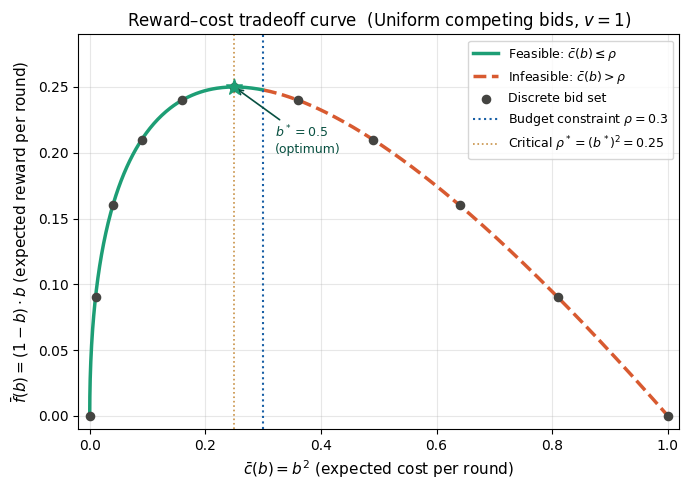

In [16]:
 # Reward–cost tradeoff curve: geometric view of the LP from Part 8
b_cont = np.linspace(0.001, 0.999, 500)
E_cost_cont = b_cont ** 2
E_reward_cont = (1 - b_cont) * b_cont

rho_critical = 0.5 ** 2  # = 0.25

fig, ax = plt.subplots(figsize=(7, 5))

# Split curve into feasible (green) and infeasible (red dashed) parts
feasible_mask = E_cost_cont <= rho
ax.plot(E_cost_cont[feasible_mask], E_reward_cont[feasible_mask],
        color="#1D9E75", lw=2.5, label="Feasible: $\\bar{c}(b) \\leq \\rho$")
ax.plot(E_cost_cont[~feasible_mask], E_reward_cont[~feasible_mask],
        color="#D85A30", lw=2.5, linestyle="--", label="Infeasible: $\\bar{c}(b) > \\rho$")

# Discrete bids from config
E_cost_d = bids ** 2
E_reward_d = (1 - bids) * bids
ax.scatter(E_cost_d, E_reward_d, color="#444441", s=35, zorder=5, label="Discrete bid set")

# Budget constraint line and critical threshold
ax.axvline(x=rho, color="#185FA5", lw=1.5, linestyle=":",
           label=f"Budget constraint $\\rho = {rho}$")
ax.axvline(x=rho_critical, color="#BA7517", lw=1.2, linestyle=":", alpha=0.8,
           label=f"Critical $\\rho^* = (b^*)^2 = {rho_critical}$")

# Optimal point b*=0.5
ax.scatter([0.25], [0.25], color="#1D9E75", s=140, zorder=6, marker="*")
ax.annotate("$b^* = 0.5$\n(optimum)", xy=(0.25, 0.25), xytext=(0.32, 0.20),
            fontsize=9, color="#085041",
            arrowprops=dict(arrowstyle="->", color="#085041", lw=1.2))

ax.set_xlabel("$\\bar{c}(b) = b^2$ (expected cost per round)", fontsize=11)
ax.set_ylabel("$\\bar{f}(b) = (1-b) \\cdot b$ (expected reward per round)", fontsize=11)
ax.set_title("Reward–cost tradeoff curve  (Uniform competing bids, $v = 1$)", fontsize=12)
ax.legend(fontsize=9, loc="upper right")
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.01, 0.29)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "results" / "plots" / "req1_reward_cost_tradeoff.png", dpi=150)
plt.show()

In [17]:
comparison_summary = pd.DataFrame(
    [
        {
            "algorithm": "ucb1",
            "rounds_played": len(ucb1_df),
            "final_round": int(ucb1_df["round"].iloc[-1]),
            "total_reward": float(ucb1_df["cumulative_reward"].iloc[-1]),
            "total_cost": float(ucb1_df["cumulative_cost"].iloc[-1]),
            "final_budget_left": float(ucb1_df["budget_left"].iloc[-1]),
            "final_cumulative_regret": float(ucb1_df["cumulative_regret"].iloc[-1]),
            "stopped_early": len(ucb1_df) < horizon,
        },
        {
            "algorithm": "budgeted_ucb",
            "rounds_played": len(budgeted_ucb_df),
            "final_round": int(budgeted_ucb_df["round"].iloc[-1]),
            "total_reward": float(budgeted_ucb_df["cumulative_reward"].iloc[-1]),
            "total_cost": float(budgeted_ucb_df["cumulative_cost"].iloc[-1]),
            "final_budget_left": float(budgeted_ucb_df["budget_left"].iloc[-1]),
            "final_cumulative_regret": float(budgeted_ucb_df["cumulative_regret"].iloc[-1]),
            "stopped_early": len(budgeted_ucb_df) < horizon,
        },
    ]
)

comparison_summary

,algorithm,rounds_played,final_round,total_reward,total_cost,final_budget_left,final_cumulative_regret,stopped_early
0,ucb1,934,934,168.7,299.3,0.7,64.8,True
1,budgeted_ucb,1000,1000,174.8,298.2,1.8,75.2,False


## Comparison of UCB1 and Budgeted UCB

The plain UCB1 learner ignores the budget constraint when selecting bids. It learns 
which bid has high expected reward, but it does not explicitly control the spending rate.

Budgeted UCB extends the UCB idea by estimating both rewards and costs. At each round, 
it uses the remaining budget and remaining horizon to choose a distribution over bids 
that respects a per-round budget target.

In the official budget setting $B=300$, the budget is not very tight because the 
unconstrained optimal bid $b=0.5$ has expected cost $0.25 < \rho=0.30$. Therefore, UCB1 
can be competitive and may even obtain slightly higher reward in a single seed.

The important comparison is not only one seed, but the average behavior over many seeds 
and the tight-budget stress test. When the budget becomes binding, the budget-aware 
algorithm should have a clearer advantage because it controls spending over time.

**A note on comparing regret under budget constraints.** In budgeted problems, raw 
cumulative regret must be interpreted carefully. If one algorithm stops early because 
it exhausts the budget, then it has fewer played rounds over which regret is accumulated.

For this reason, we mainly report:

1. total reward and total cost,
2. number of rounds played,
3. early stopping rate,
4. pseudo-regret against the analytical/LP benchmark.

The LP-benchmark pseudo-regret is the most informative regret measure for the budgeted 
setting, because it compares the algorithms with the best expected budget-feasible 
bidding distribution.

In [18]:
ucb1_path = save_algorithm_results(
    ucb1_rows,
    PROJECT_ROOT / outputs_config["ucb1_results_file"],
)

budgeted_ucb_path = save_algorithm_results(
    budgeted_ucb_rows,
    PROJECT_ROOT / outputs_config["budgeted_ucb_results_file"],
)

print("UCB1 CSV path:", ucb1_path)
print("Budgeted UCB CSV path:", budgeted_ucb_path)
print("UCB1 CSV exists:", ucb1_path.exists())
print("Budgeted UCB CSV exists:", budgeted_ucb_path.exists())

Saved 934 rows to /Users/foadzahedilabaf/Projects/ola-project/results/raw/req1_ucb1.csv
Saved 1000 rows to /Users/foadzahedilabaf/Projects/ola-project/results/raw/req1_budgeted_ucb.csv
UCB1 CSV path: /Users/foadzahedilabaf/Projects/ola-project/results/raw/req1_ucb1.csv
Budgeted UCB CSV path: /Users/foadzahedilabaf/Projects/ola-project/results/raw/req1_budgeted_ucb.csv
UCB1 CSV exists: True
Budgeted UCB CSV exists: True


In [19]:
from ola.utils.plotting import load_result_csvs

combined_results = load_result_csvs([ucb1_path, budgeted_ucb_path])

print("Combined results shape:", combined_results.shape)
print("Algorithms in combined results:")
print(combined_results["algorithm"].value_counts())

display(combined_results.head())
display(combined_results.tail())

Combined results shape: (1934, 20)
Algorithms in combined results:
algorithm
budgeted_ucb    1000
ucb1             934
Name: count, dtype: int64


,algorithm,round,action,bids,wins,reward,cost,budget_left,cumulative_reward,cumulative_cost,benchmark_reward,instant_regret,cumulative_regret,highest_competing_bid,done,effective_bid,full_horizon_regret,average_full_horizon_regret,missing_rounds_after_stop,stopped_early
0,ucb1,1,0.0,0.0,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,0.25,0.773956,False,0.0,NaN,NaN,NaN,NaN
1,ucb1,2,0.1,0.1,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,0.50,0.438878,False,0.1,NaN,NaN,NaN,NaN
2,ucb1,3,0.2,0.2,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,0.75,0.858598,False,0.2,NaN,NaN,NaN,NaN
3,ucb1,4,0.3,0.3,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,1.00,0.697368,False,0.3,NaN,NaN,NaN,NaN
4,ucb1,5,0.4,0.4,1,0.6,0.4,299.6,0.6,0.4,0.25,-0.35,0.65,0.094177,False,0.4,NaN,NaN,NaN,NaN


,algorithm,round,action,bids,wins,reward,cost,budget_left,cumulative_reward,cumulative_cost,benchmark_reward,instant_regret,cumulative_regret,highest_competing_bid,done,effective_bid,full_horizon_regret,average_full_horizon_regret,missing_rounds_after_stop,stopped_early
1929,budgeted_ucb,996,0.4,0.4,0,0.0,0.0,3.5,174.5,296.5,0.25,0.25,74.50,0.437990,False,0.4,NaN,NaN,NaN,NaN
1930,budgeted_ucb,997,0.5,0.5,0,0.0,0.0,3.5,174.5,296.5,0.25,0.25,74.75,0.639014,False,0.5,NaN,NaN,NaN,NaN
1931,budgeted_ucb,998,1.0,1.0,1,0.0,1.0,2.5,174.5,297.5,0.25,0.25,75.00,0.002309,False,1.0,NaN,NaN,NaN,NaN
1932,budgeted_ucb,999,0.0,0.0,0,0.0,0.0,2.5,174.5,297.5,0.25,0.25,75.25,0.993368,False,0.0,NaN,NaN,NaN,NaN
1933,budgeted_ucb,1000,0.7,0.7,1,0.3,0.7,1.8,174.8,298.2,0.25,-0.05,75.20,0.280896,True,0.7,75.2,0.0752,0.0,False


Saved plot to /Users/foadzahedilabaf/Projects/ola-project/results/plots/req1_cumulative_reward.png
Saved plot to /Users/foadzahedilabaf/Projects/ola-project/results/plots/req1_budget_left.png
Saved plot to /Users/foadzahedilabaf/Projects/ola-project/results/plots/req1_cumulative_cost.png
Saved plot to /Users/foadzahedilabaf/Projects/ola-project/results/plots/req1_selected_bid.png


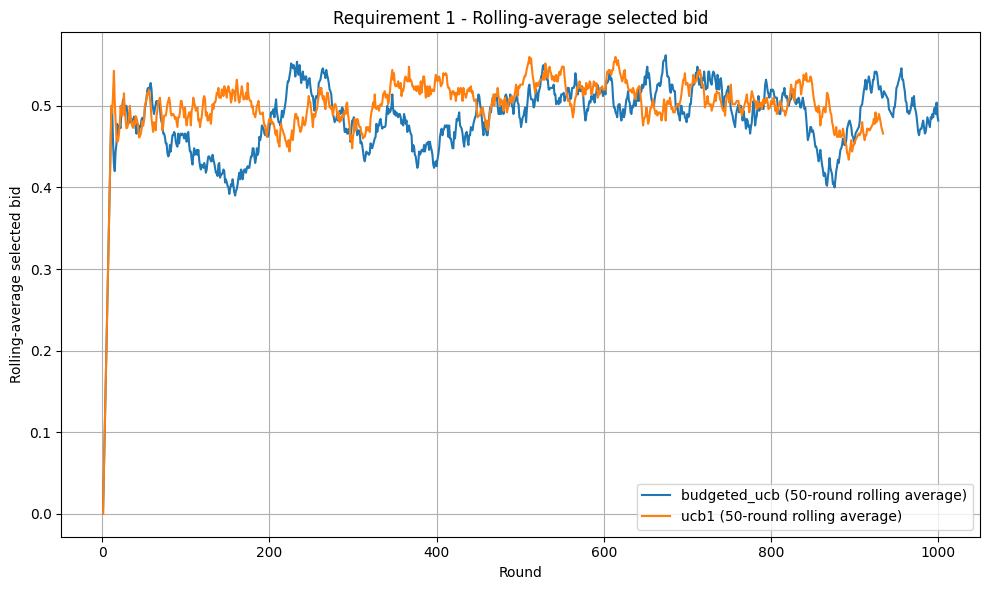

Plots directory: /Users/foadzahedilabaf/Projects/ola-project/results/plots
req1_cumulative_reward.png exists: True
req1_budget_left.png exists: True
req1_cumulative_cost.png exists: True
req1_selected_bid.png exists: True
req1_rolling_average_selected_bid.png exists: True


In [20]:
from ola.utils.plotting import generate_standard_req1_plots

plots_dir = PROJECT_ROOT / "results" / "plots"

# Generate the standard project plots.
generate_standard_req1_plots(
    dataframe=combined_results,
    plots_dir=plots_dir,
)

# Add an extra readability plot for selected bids.
# The raw selected-bid plot is correct, but very noisy because it shows every action.
rolling_window = 50

plt.figure(figsize=(10, 6))

for algorithm_name, group in combined_results.groupby("algorithm"):
    sorted_group = group.sort_values("round").copy()
    sorted_group["rolling_average_bid"] = (
        sorted_group["action"]
        .rolling(window=rolling_window, min_periods=1)
        .mean()
    )

    plt.plot(
        sorted_group["round"],
        sorted_group["rolling_average_bid"],
        label=f"{algorithm_name} ({rolling_window}-round rolling average)",
    )

plt.xlabel("Round")
plt.ylabel("Rolling-average selected bid")
plt.title("Requirement 1 - Rolling-average selected bid")
plt.legend()
plt.grid(True)
plt.tight_layout()

rolling_bid_plot_path = plots_dir / "req1_rolling_average_selected_bid.png"
plt.savefig(rolling_bid_plot_path, dpi=200)
plt.show()

expected_plot_files = [
    "req1_cumulative_reward.png",
    "req1_budget_left.png",
    "req1_cumulative_cost.png",
    "req1_selected_bid.png",
    "req1_rolling_average_selected_bid.png",
]

print("Plots directory:", plots_dir)

for filename in expected_plot_files:
    plot_path = plots_dir / filename
    print(filename, "exists:", plot_path.exists())

req1_cumulative_reward.png


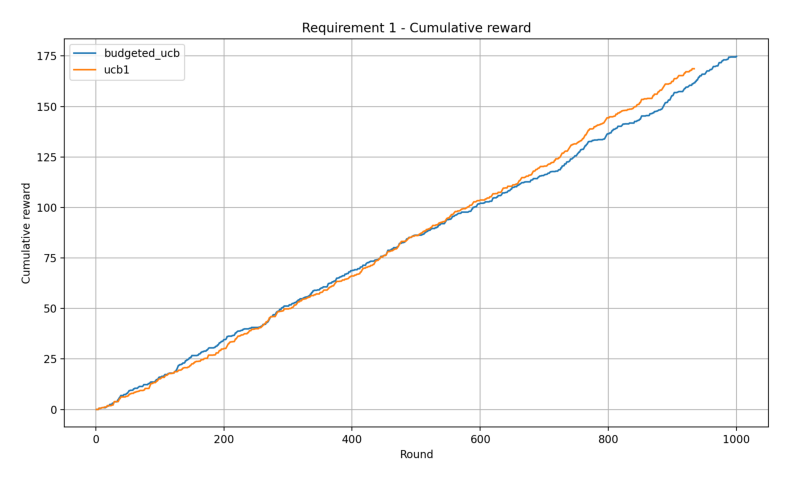

req1_budget_left.png


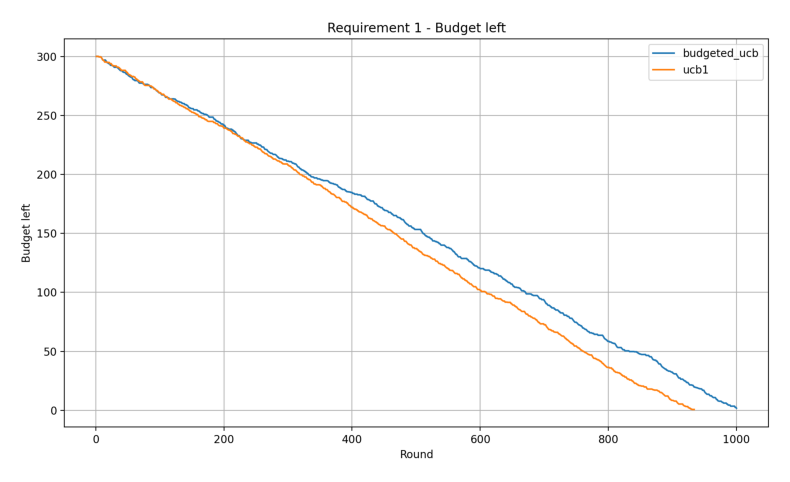

req1_cumulative_cost.png


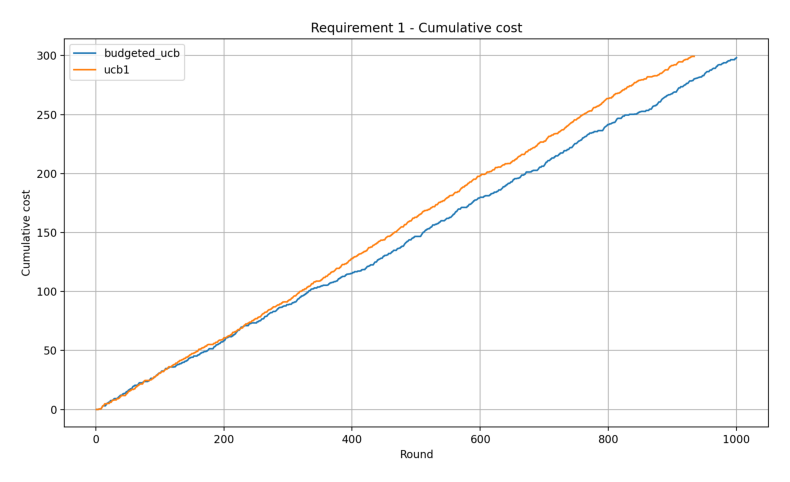

req1_selected_bid.png


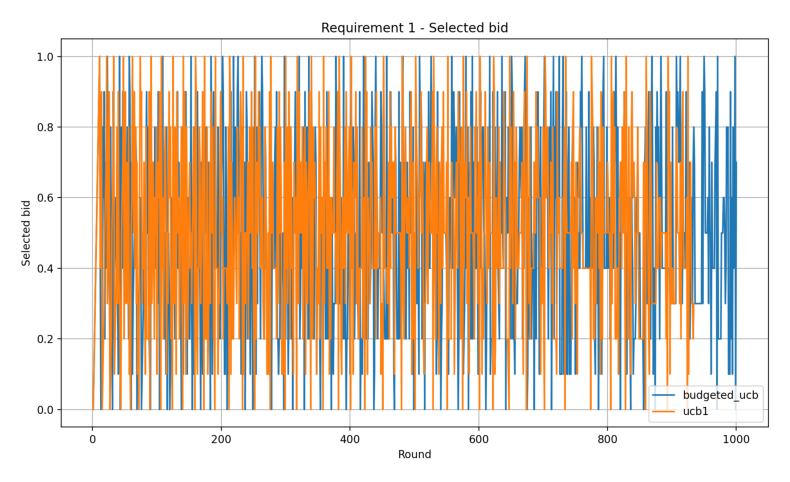

req1_rolling_average_selected_bid.png


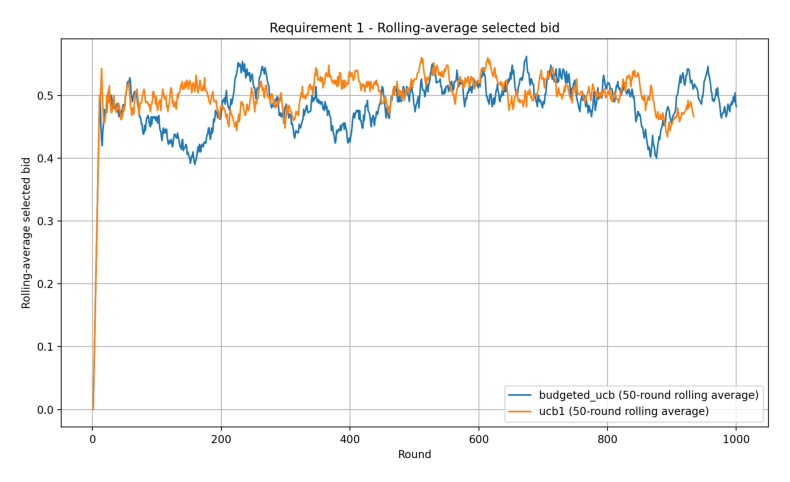

In [21]:
plot_paths = [
    plots_dir / "req1_cumulative_reward.png",
    plots_dir / "req1_budget_left.png",
    plots_dir / "req1_cumulative_cost.png",
    plots_dir / "req1_selected_bid.png",
    plots_dir / "req1_rolling_average_selected_bid.png",
]

for plot_path in plot_paths:
    print(plot_path.name)
    img = plt.imread(plot_path)

    plt.figure(figsize=(10, 6))
    plt.imshow(img)
    plt.axis("off")
    plt.show()

The cumulative reward plot shows the realized reward collected by each algorithm over 
time. In the official configuration, the budget is relatively loose, so UCB1 can be 
competitive with Budgeted UCB.

The budget-left and cumulative-cost plots show the main behavioral difference. UCB1 
selects bids only according to reward optimism and does not explicitly pace the budget. 
Budgeted UCB instead uses remaining budget and remaining rounds to control spending.

This difference becomes more important when the budget is tighter, as shown in the 
multi-seed stress test.

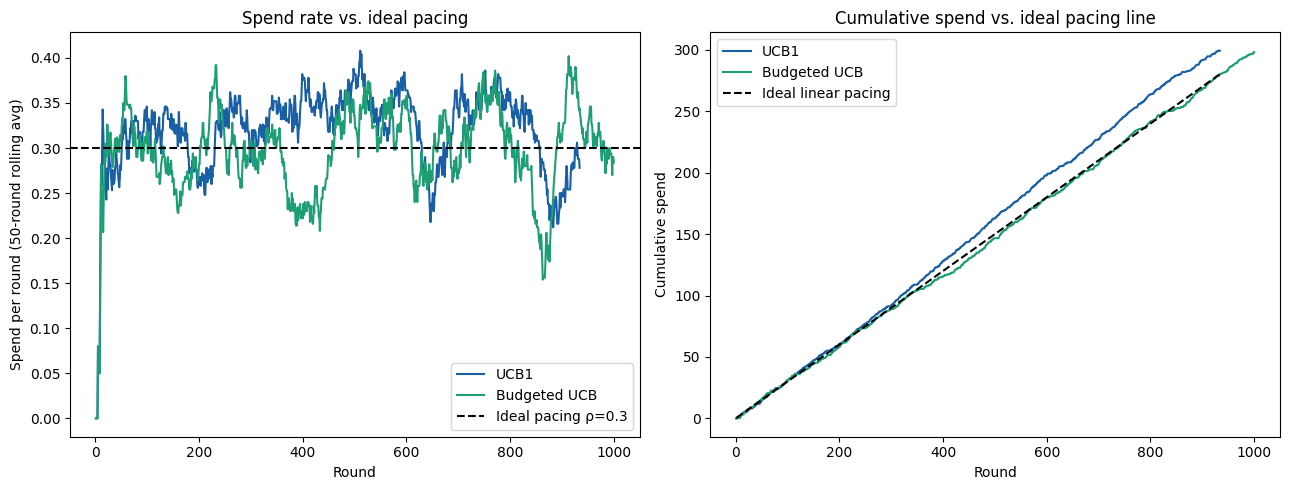

Mean absolute pacing error — UCB1: 10.834
Mean absolute pacing error — Budgeted UCB: 1.866


In [22]:
# ── Budget pacing: spend rate vs. ideal linear pacing ───────────────────────
rho_ideal = initial_budget / horizon
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for df, name, color in [(ucb1_df, "UCB1", "#185FA5"), (budgeted_ucb_df, "Budgeted UCB", "#1D9E75")]:
    rolling_spend = df["cost"].rolling(window=50, min_periods=1).mean()
    axes[0].plot(df["round"], rolling_spend, label=name, color=color)
axes[0].axhline(rho_ideal, color="black", linestyle="--", label=f"Ideal pacing ρ={rho_ideal}")
axes[0].set_xlabel("Round")
axes[0].set_ylabel("Spend per round (50-round rolling avg)")
axes[0].set_title("Spend rate vs. ideal pacing")
axes[0].legend()

for df, name, color in [(ucb1_df, "UCB1", "#185FA5"), (budgeted_ucb_df, "Budgeted UCB", "#1D9E75")]:
    axes[1].plot(df["round"], df["cumulative_cost"], label=name, color=color)
axes[1].plot(ucb1_df["round"], rho_ideal * ucb1_df["round"], "k--", label="Ideal linear pacing")
axes[1].set_xlabel("Round")
axes[1].set_ylabel("Cumulative spend")
axes[1].set_title("Cumulative spend vs. ideal pacing line")
axes[1].legend()

plt.tight_layout()
plt.savefig(plots_dir / "req1_budget_pacing.png", dpi=200)
plt.show()

pacing_error_ucb1 = (ucb1_df["cumulative_cost"] - rho_ideal * ucb1_df["round"]).abs().mean()
pacing_error_budgeted = (budgeted_ucb_df["cumulative_cost"] - rho_ideal * budgeted_ucb_df["round"]).abs().mean()
print("Mean absolute pacing error — UCB1:", round(pacing_error_ucb1, 3))
print("Mean absolute pacing error — Budgeted UCB:", round(pacing_error_budgeted, 3))

## Additional robustness experiments: multiple seeds and tighter budget

The previous experiment uses one fixed random seed. This is useful for debugging and reproducibility, but the environment is stochastic. A stronger empirical evaluation repeats the experiment over multiple independent seeds.

In this section, we run both algorithms over several random seeds and report mean and standard deviation. We do this for two settings:

1. the official project configuration, with budget `B = 300`;
2. a tighter-budget stress test, with budget `B = 150`.

The stress test is not a replacement for the official configuration. It is an additional diagnostic experiment that makes the budget constraint more binding and helps us understand when budget-aware learning becomes more important.

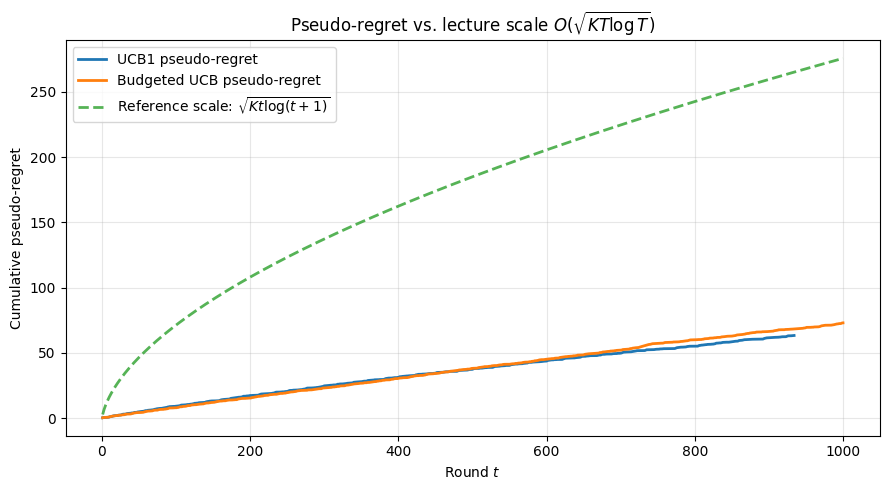

UCB1 ran for 934 rounds (stopped early: True)
Budgeted UCB ran for 1000 rounds (stopped early: False)
Final cumulative pseudo-regret (UCB1): 63.29
Final cumulative pseudo-regret (Budgeted UCB): 72.96
Lecture reference scale at T=1000: 275.6743


In [23]:
# ── Sublinear pseudo-regret verification: linear-scale lecture-aligned plot ────

fig, ax = plt.subplots(figsize=(9, 5))

K = len(bids)

def lecture_reference_scale(n_rounds):
    """
    Lecture-aligned UCB1 instance-independent scale:
        O(sqrt(K T log T))

    We plot sqrt(K t log(t+1)) only as a reference scale.
    No constant such as 8 is shown, because Big-O ignores constants.
    """
    t_range = np.arange(1, n_rounds + 1)
    reference = np.sqrt(K * t_range * np.log(t_range + 1))
    return t_range, reference


def add_pseudo_regret(df, value=1.0):
    """
    Compute cumulative pseudo-regret using expected rewards.

    In Req 1:
        m ~ Uniform(0,1)
        P(win | b) = b
        reward if win = value - b

    So:
        expected_reward(b) = (value - b) * b

    For value = 1:
        b* = 0.5
        expected_reward(b*) = 0.25
    """
    df = df.copy()

    optimal_bid = value / 2
    optimal_expected_reward = (value - optimal_bid) * optimal_bid

    df["expected_reward_action"] = (value - df["action"]) * df["action"]

    df["instant_pseudo_regret"] = (
        optimal_expected_reward - df["expected_reward_action"]
    )

    df["instant_pseudo_regret"] = df["instant_pseudo_regret"].clip(lower=0)
    df["cumulative_pseudo_regret"] = df["instant_pseudo_regret"].cumsum()

    return df


ucb1_df_plot = add_pseudo_regret(ucb1_df, value=value)
budgeted_ucb_df_plot = add_pseudo_regret(budgeted_ucb_df, value=value)

ucb1_t_range, ucb1_reference = lecture_reference_scale(len(ucb1_df_plot))
budgeted_t_range, budgeted_reference = lecture_reference_scale(len(budgeted_ucb_df_plot))

# Use the full horizon reference, because Budgeted UCB reaches T=1000.
full_t_range, full_reference = lecture_reference_scale(horizon)

ax.plot(
    ucb1_df_plot["round"],
    ucb1_df_plot["cumulative_pseudo_regret"],
    label="UCB1 pseudo-regret",
    linewidth=2,
)

ax.plot(
    budgeted_ucb_df_plot["round"],
    budgeted_ucb_df_plot["cumulative_pseudo_regret"],
    label="Budgeted UCB pseudo-regret",
    linewidth=2,
)

ax.plot(
    full_t_range,
    full_reference,
    "--",
    label=r"Reference scale: $\sqrt{Kt\log(t+1)}$",
    linewidth=2,
    alpha=0.8,
)

ax.set_xlabel("Round $t$")
ax.set_ylabel("Cumulative pseudo-regret")
ax.set_title(r"Pseudo-regret vs. lecture scale $O(\sqrt{KT\log T})$")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(plots_dir / "req1_pseudo_regret_linear_lecture_scale.png", dpi=200)
plt.show()

print(f"UCB1 ran for {len(ucb1_df_plot)} rounds (stopped early: {len(ucb1_df_plot) < horizon})")
print(f"Budgeted UCB ran for {len(budgeted_ucb_df_plot)} rounds (stopped early: {len(budgeted_ucb_df_plot) < horizon})")

print(
    "Final cumulative pseudo-regret (UCB1):",
    round(ucb1_df_plot["cumulative_pseudo_regret"].iloc[-1], 4),
)

print(
    "Final cumulative pseudo-regret (Budgeted UCB):",
    round(budgeted_ucb_df_plot["cumulative_pseudo_regret"].iloc[-1], 4),
)

print(
    "Lecture reference scale at T=1000:",
    round(full_reference[-1], 4),
)

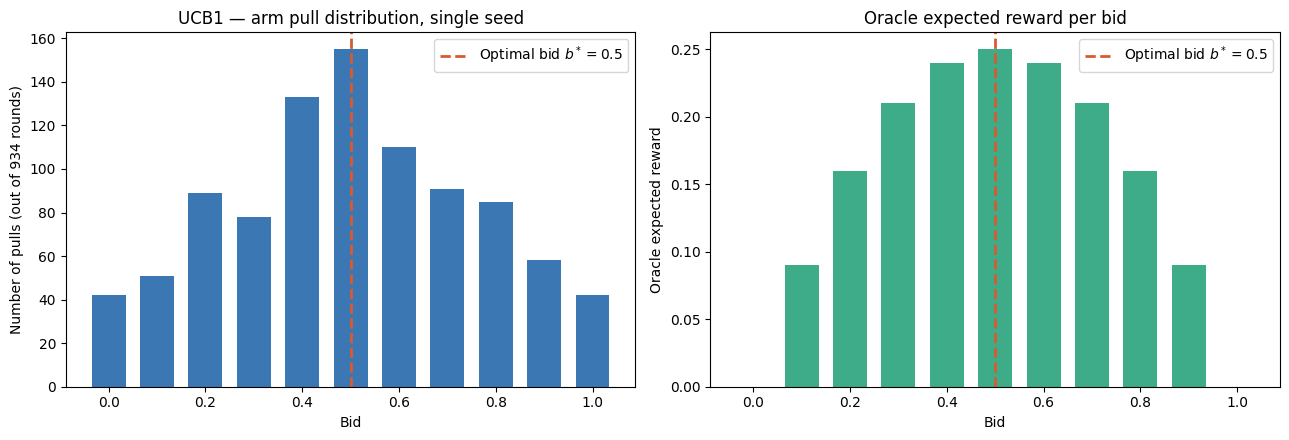

Most-pulled bid: 0.5
Share of played rounds spent on optimal bid (0.5): 0.166
Rounds played by UCB1 in this single seed: 934


In [24]:
# ── Arm pull distribution vs. oracle expected reward, single seed ────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

pull_counts = ucb1_df["action"].value_counts().reindex(bids, fill_value=0)

axes[0].bar(bids, pull_counts.values, width=0.07, color="#185FA5", alpha=0.85)
axes[0].axvline(
    0.5,
    color="#D85A30",
    linestyle="--",
    linewidth=2,
    label="Optimal bid $b^*=0.5$",
)
axes[0].set_xlabel("Bid")
axes[0].set_ylabel(f"Number of pulls (out of {len(ucb1_df)} rounds)")
axes[0].set_title("UCB1 — arm pull distribution, single seed")
axes[0].legend()

oracle_reward = (value - bids) * bids

axes[1].bar(bids, oracle_reward, width=0.07, color="#1D9E75", alpha=0.85)
axes[1].axvline(
    0.5,
    color="#D85A30",
    linestyle="--",
    linewidth=2,
    label="Optimal bid $b^*=0.5$",
)
axes[1].set_xlabel("Bid")
axes[1].set_ylabel("Oracle expected reward")
axes[1].set_title("Oracle expected reward per bid")
axes[1].legend()

plt.tight_layout()
plt.savefig(plots_dir / "req1_arm_pull_distribution_single_seed.png", dpi=200)
plt.show()

print("Most-pulled bid:", pull_counts.idxmax())
print(
    "Share of played rounds spent on optimal bid (0.5):",
    round(pull_counts.loc[0.5] / pull_counts.sum(), 3),
)
print("Rounds played by UCB1 in this single seed:", len(ucb1_df))

In [25]:
MULTI_SEED_VALUES = list(range(30))


def run_req1_for_seed(seed, budget, label):
    """Run both Req 1 algorithms for one seed and one budget setting."""
    ucb1_benchmark_seed, budgeted_ucb_benchmark_seed = compute_req1_benchmarks(
        bids=bids,
        value=value,
        initial_budget=budget,
        horizon=horizon,
        min_competing_bid=min_competing_bid,
        max_competing_bid=max_competing_bid,
    )

    ucb1_seed = UCB1(actions=bids, horizon=horizon)
    ucb1_seed_rows = run_algorithm(
        algorithm_name="ucb1",
        learner=ucb1_seed,
        value=value,
        initial_budget=budget,
        horizon=horizon,
        random_seed=seed,
        min_competing_bid=min_competing_bid,
        max_competing_bid=max_competing_bid,
        benchmark_reward_per_round=ucb1_benchmark_seed,
    )

    budgeted_ucb_seed = BudgetedUCB(
        actions=bids,
        horizon=horizon,
        initial_budget=budget,
    )
    budgeted_ucb_seed_rows = run_algorithm(
        algorithm_name="budgeted_ucb",
        learner=budgeted_ucb_seed,
        value=value,
        initial_budget=budget,
        horizon=horizon,
        random_seed=seed,
        min_competing_bid=min_competing_bid,
        max_competing_bid=max_competing_bid,
        benchmark_reward_per_round=budgeted_ucb_benchmark_seed,
    )

    seed_df = pd.DataFrame(ucb1_seed_rows + budgeted_ucb_seed_rows)
    seed_df["seed"] = seed
    seed_df["budget_setting"] = label
    seed_df["initial_budget"] = budget

    return seed_df


multi_seed_frames = []

for seed in MULTI_SEED_VALUES:
    multi_seed_frames.append(
        run_req1_for_seed(
            seed=seed,
            budget=initial_budget,
            label="official_budget_B_300",
        )
    )
    multi_seed_frames.append(
        run_req1_for_seed(
            seed=seed,
            budget=150.0,
            label="tight_budget_B_150",
        )
    )

multi_seed_results = pd.concat(multi_seed_frames, ignore_index=True)

print("Multi-seed result shape:", multi_seed_results.shape)
print("Number of seeds:", multi_seed_results["seed"].nunique())
print("Budget settings:")
print(multi_seed_results["budget_setting"].value_counts())
print("\nAlgorithms:")
print(multi_seed_results["algorithm"].value_counts())

Multi-seed result shape: (102329, 23)
Number of seeds: 30
Budget settings:
budget_setting
official_budget_B_300    58431
tight_budget_B_150       43898
Name: count, dtype: int64

Algorithms:
algorithm
budgeted_ucb    60000
ucb1            42329
Name: count, dtype: int64


In [26]:
multi_seed_summary = (
    multi_seed_results
    .sort_values(["budget_setting", "seed", "algorithm", "round"])
    .groupby(["budget_setting", "initial_budget", "seed", "algorithm"])
    .agg(
        rounds_played=("round", "max"),
        total_reward=("cumulative_reward", "last"),
        total_cost=("cumulative_cost", "last"),
        final_budget_left=("budget_left", "last"),
        final_cumulative_regret=("cumulative_regret", "last"),
    )
    .reset_index()
)

multi_seed_aggregate_summary = (
    multi_seed_summary
    .groupby(["budget_setting", "initial_budget", "algorithm"])
    .agg(
        mean_rounds_played=("rounds_played", "mean"),
        std_rounds_played=("rounds_played", "std"),
        mean_total_reward=("total_reward", "mean"),
        std_total_reward=("total_reward", "std"),
        mean_total_cost=("total_cost", "mean"),
        std_total_cost=("total_cost", "std"),
        mean_final_budget_left=("final_budget_left", "mean"),
        std_final_budget_left=("final_budget_left", "std"),
        early_stop_rate=("rounds_played", lambda values: float((values < horizon).mean())),
    )
    .reset_index()
)

multi_seed_aggregate_summary

,budget_setting,initial_budget,algorithm,mean_rounds_played,std_rounds_played,mean_total_reward,std_total_reward,mean_total_cost,std_total_cost,mean_final_budget_left,std_final_budget_left,early_stop_rate
0,official_budget_B_300,300.0,budgeted_ucb,1000.000000,0.000000,180.396667,7.968623,299.470000,1.893391,0.530000,1.893391,0.000000
1,official_budget_B_300,300.0,ucb1,947.700000,26.839433,170.733333,8.271402,299.466667,0.507416,0.533333,0.507416,0.933333
2,tight_budget_B_150,150.0,budgeted_ucb,1000.000000,0.000000,170.513333,6.650835,149.820000,0.228035,0.180000,0.228035,0.000000
3,tight_budget_B_150,150.0,ucb1,463.266667,17.978787,78.716667,5.153444,149.616667,0.218274,0.383333,0.218274,1.000000


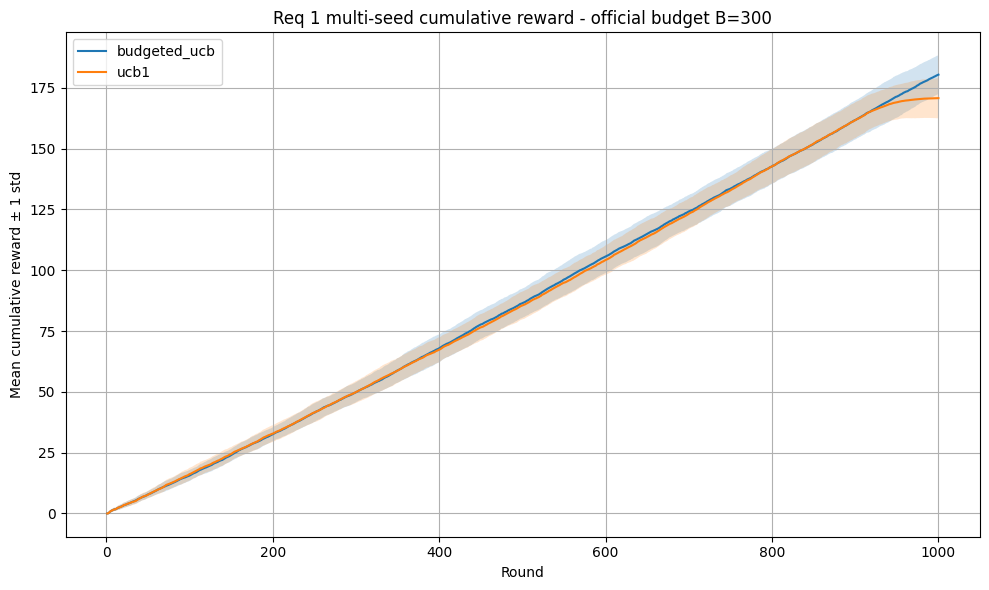

Saved plot to: /Users/foadzahedilabaf/Projects/ola-project/results/plots/req1_multiseed_reward_official_budget.png
Plot exists: True


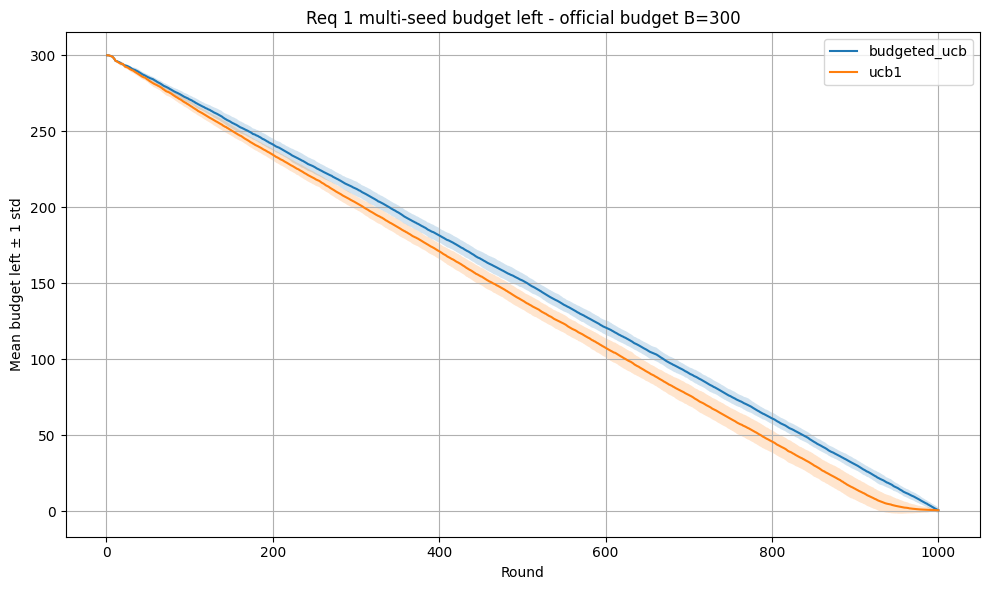

Saved plot to: /Users/foadzahedilabaf/Projects/ola-project/results/plots/req1_multiseed_budget_left_official_budget.png
Plot exists: True


In [27]:
def plot_mean_with_std_band(dataframe, budget_setting, metric, ylabel, title, output_filename):
    """Plot mean trajectory with plus/minus one standard deviation over seeds."""
    setting_df = dataframe[dataframe["budget_setting"] == budget_setting]

    plt.figure(figsize=(10, 6))

    for algorithm_name, group in setting_df.groupby("algorithm"):
        pivot = group.pivot_table(
            index="round",
            columns="seed",
            values=metric,
            aggfunc="last",
        ).sort_index()

        # Forward-fill so seeds that stopped early hold their last value
        # instead of disappearing from the mean for the remaining rounds.
        pivot = pivot.reindex(range(1, horizon + 1)).ffill()

        mean_values = pivot.mean(axis=1)
        std_values = pivot.std(axis=1).fillna(0.0)

        rounds = mean_values.index.to_numpy(dtype=float)
        mean_array = mean_values.to_numpy(dtype=float)
        std_array = std_values.to_numpy(dtype=float)

        plt.plot(rounds, mean_array, label=algorithm_name)
        plt.fill_between(
            rounds,
            mean_array - std_array,
            mean_array + std_array,
            alpha=0.2,
        )

    plt.xlabel("Round")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    output_path = plots_dir / output_filename
    plt.savefig(output_path, dpi=200)
    plt.show()

    print("Saved plot to:", output_path)
    print("Plot exists:", output_path.exists())


plot_mean_with_std_band(
    dataframe=multi_seed_results,
    budget_setting="official_budget_B_300",
    metric="cumulative_reward",
    ylabel="Mean cumulative reward ± 1 std",
    title="Req 1 multi-seed cumulative reward - official budget B=300",
    output_filename="req1_multiseed_reward_official_budget.png",
)

plot_mean_with_std_band(
    dataframe=multi_seed_results,
    budget_setting="official_budget_B_300",
    metric="budget_left",
    ylabel="Mean budget left ± 1 std",
    title="Req 1 multi-seed budget left - official budget B=300",
    output_filename="req1_multiseed_budget_left_official_budget.png",
)

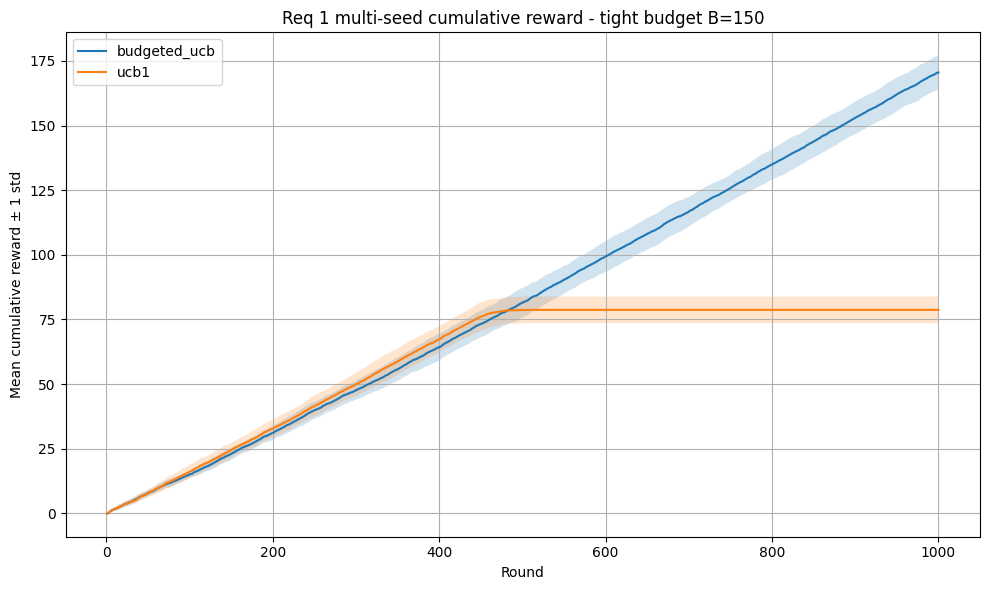

Saved plot to: /Users/foadzahedilabaf/Projects/ola-project/results/plots/req1_multiseed_reward_tight_budget.png
Plot exists: True


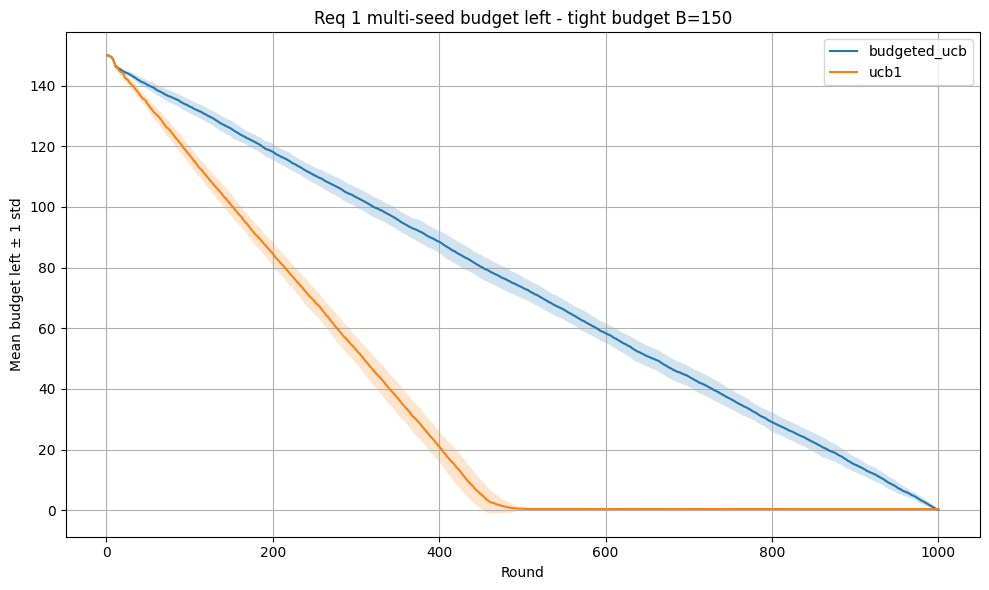

Saved plot to: /Users/foadzahedilabaf/Projects/ola-project/results/plots/req1_multiseed_budget_left_tight_budget.png
Plot exists: True


In [28]:
plot_mean_with_std_band(
    dataframe=multi_seed_results,
    budget_setting="tight_budget_B_150",
    metric="cumulative_reward",
    ylabel="Mean cumulative reward ± 1 std",
    title="Req 1 multi-seed cumulative reward - tight budget B=150",
    output_filename="req1_multiseed_reward_tight_budget.png",
)

plot_mean_with_std_band(
    dataframe=multi_seed_results,
    budget_setting="tight_budget_B_150",
    metric="budget_left",
    ylabel="Mean budget left ± 1 std",
    title="Req 1 multi-seed budget left - tight budget B=150",
    output_filename="req1_multiseed_budget_left_tight_budget.png",
)

In [29]:
#Regret 
def expected_reward(b, value=1.0):
    return (value - b) * b


def expected_cost(b):
    return b ** 2


def solve_lp_benchmark(bids, value, horizon, initial_budget, tol=1e-12):
    bids_arr = np.array(bids, dtype=float)
    rewards = np.array([expected_reward(b, value) for b in bids_arr])
    costs = np.array([expected_cost(b) for b in bids_arr])

    rho = initial_budget / horizon
    n = len(bids_arr)

    best_dist = np.zeros(n)
    best_value = -np.inf

    def update_best(dist):
        nonlocal best_dist, best_value
        obj = float(np.dot(dist, rewards))
        if obj > best_value + tol:
            best_value = obj
            best_dist = dist.copy()

    for i in range(n):
        if costs[i] <= rho + tol:
            dist = np.zeros(n)
            dist[i] = 1.0
            update_best(dist)

    for i in range(n):
        for j in range(i + 1, n):
            ci, cj = costs[i], costs[j]

            if abs(ci - cj) <= tol:
                continue

            p_i = (rho - cj) / (ci - cj)
            p_j = 1.0 - p_i

            if -tol <= p_i <= 1.0 + tol and -tol <= p_j <= 1.0 + tol:
                dist = np.zeros(n)
                dist[i] = np.clip(p_i, 0.0, 1.0)
                dist[j] = np.clip(p_j, 0.0, 1.0)
                update_best(dist)

    if best_value == -np.inf:
        raise ValueError("No feasible benchmark found.")

    return {
        "rho": rho,
        "bids": bids_arr,
        "rewards": rewards,
        "costs": costs,
        "dist": best_dist,
        "opt": float(best_value),
        "opt_cost": float(np.dot(best_dist, costs)),
    }


def lp_pseudo_regret(
    data,
    bids,
    value,
    horizon,
    initial_budget,
    bid_column="effective_bid",
):
    bench = solve_lp_benchmark(
        bids=bids,
        value=value,
        horizon=horizon,
        initial_budget=initial_budget,
    )

    opt = bench["opt"]
    frames = []

    for algo in sorted(data["algorithm"].unique()):
        algo_data = data[data["algorithm"] == algo].copy()

        seeds = sorted(algo_data["seed"].unique()) if "seed" in algo_data.columns else [None]

        for seed in seeds:
            if seed is None:
                df = algo_data.copy()
            else:
                df = algo_data[algo_data["seed"] == seed].copy()

            df = df.sort_values("round").copy()

            if df.empty:
                continue

            used_col = bid_column if bid_column in df.columns else "action"
            played_bids = df[used_col].astype(float).to_numpy()
            played_rewards = np.array([expected_reward(b, value) for b in played_bids])

            df["lp_expected_reward"] = played_rewards
            df["lp_cumulative_expected_reward"] = df["lp_expected_reward"].cumsum()

            full = pd.DataFrame({"round": np.arange(1, horizon + 1)})

            full = full.merge(
                df[["round", "lp_cumulative_expected_reward"]],
                on="round",
                how="left",
            )

            full["lp_cumulative_expected_reward"] = (
                full["lp_cumulative_expected_reward"]
                .ffill()
                .fillna(0.0)
            )

            full["lp_cumulative_pseudo_regret"] = (
                full["round"] * opt - full["lp_cumulative_expected_reward"]
            )

            full["lp_average_pseudo_regret"] = (
                full["lp_cumulative_pseudo_regret"] / full["round"]
            )

            full["algorithm"] = algo

            if seed is not None:
                full["seed"] = seed

            frames.append(full)

    regret_df = pd.concat(frames, ignore_index=True)

    return regret_df, bench


def show_lp_benchmark(bench):
    out = pd.DataFrame({
        "bid": bench["bids"],
        "probability": bench["dist"],
        "expected_reward": bench["rewards"],
        "expected_cost": bench["costs"],
    })

    print("rho:", round(bench["rho"], 6))
    print("benchmark reward:", round(bench["opt"], 6))
    print("benchmark cost:", round(bench["opt_cost"], 6))

    display(out[out["probability"] > 1e-10])

    return out

rho: 0.15
benchmark reward: 0.235714
benchmark cost: 0.15


,bid,probability,expected_reward,expected_cost
3,0.3,0.142857,0.21,0.09
4,0.4,0.857143,0.24,0.16


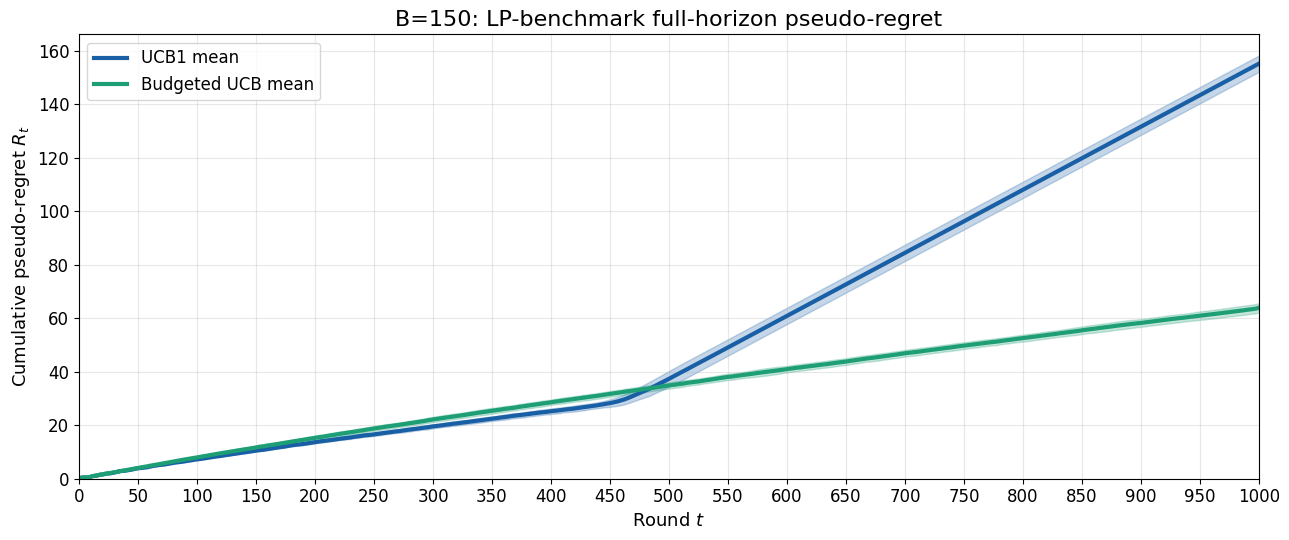

Using budget setting: tight_budget_B_150
Final mean LP pseudo-regret B=150 (UCB1): 155.14
Final mean LP pseudo-regret B=150 (Budgeted UCB): 63.92


In [30]:
# Tight budget B=150 LP-benchmark pseudo-regret over 30 seeds

budget_filter = "tight_budget_B_150"

tight_data = multi_seed_results[
    multi_seed_results["budget_setting"] == budget_filter
].copy()

lp_regret_B150_df, lp_bench_B150 = lp_pseudo_regret(
    data=tight_data,
    bids=bids,
    value=value,
    horizon=horizon,
    initial_budget=150,
    bid_column="effective_bid",
)

show_lp_benchmark(lp_bench_B150)

fig, ax = plt.subplots(figsize=(13, 5.5))

final_mean_pseudo_regret_B150 = {}

for algo in ["ucb1", "budgeted_ucb"]:
    color = "#185FA5" if algo == "ucb1" else "#1D9E75"
    label = "UCB1" if algo == "ucb1" else "Budgeted UCB"

    pivot = lp_regret_B150_df[
        lp_regret_B150_df["algorithm"] == algo
    ].pivot_table(
        index="round",
        columns="seed",
        values="lp_cumulative_pseudo_regret",
        aggfunc="last",
    ).sort_index()

    mean_regret = pivot.mean(axis=1).to_numpy(dtype=float)
    std_regret = pivot.std(axis=1).fillna(0).to_numpy(dtype=float)
    rounds = pivot.index.to_numpy(dtype=float)

    final_mean_pseudo_regret_B150[algo] = mean_regret[-1]

    ax.plot(rounds, mean_regret, label=f"{label} mean", color=color, lw=3)
    ax.fill_between(
        rounds,
        mean_regret - std_regret,
        mean_regret + std_regret,
        color=color,
        alpha=0.25,
    )

ax.set_xlim(0, horizon)
ax.set_ylim(bottom=0)
ax.set_xticks(np.arange(0, horizon + 1, 50))
ax.set_xlabel("Round $t$", fontsize=13)
ax.set_ylabel("Cumulative pseudo-regret $R_t$", fontsize=13)
ax.set_title("B=150: LP-benchmark full-horizon pseudo-regret", fontsize=16)
ax.tick_params(axis="both", labelsize=12)
ax.grid(True, alpha=0.3)
ax.legend(loc="upper left", fontsize=12, frameon=True)

plt.tight_layout()
plt.savefig(
    plots_dir / "req1_lp_pseudo_regret_B150.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

print("Using budget setting:", budget_filter)
print("Final mean LP pseudo-regret B=150 (UCB1):", round(final_mean_pseudo_regret_B150["ucb1"], 2))
print("Final mean LP pseudo-regret B=150 (Budgeted UCB):", round(final_mean_pseudo_regret_B150["budgeted_ucb"], 2))

rho: 0.3
benchmark reward: 0.25
benchmark cost: 0.25


,bid,probability,expected_reward,expected_cost
5,0.5,1.0,0.25,0.25


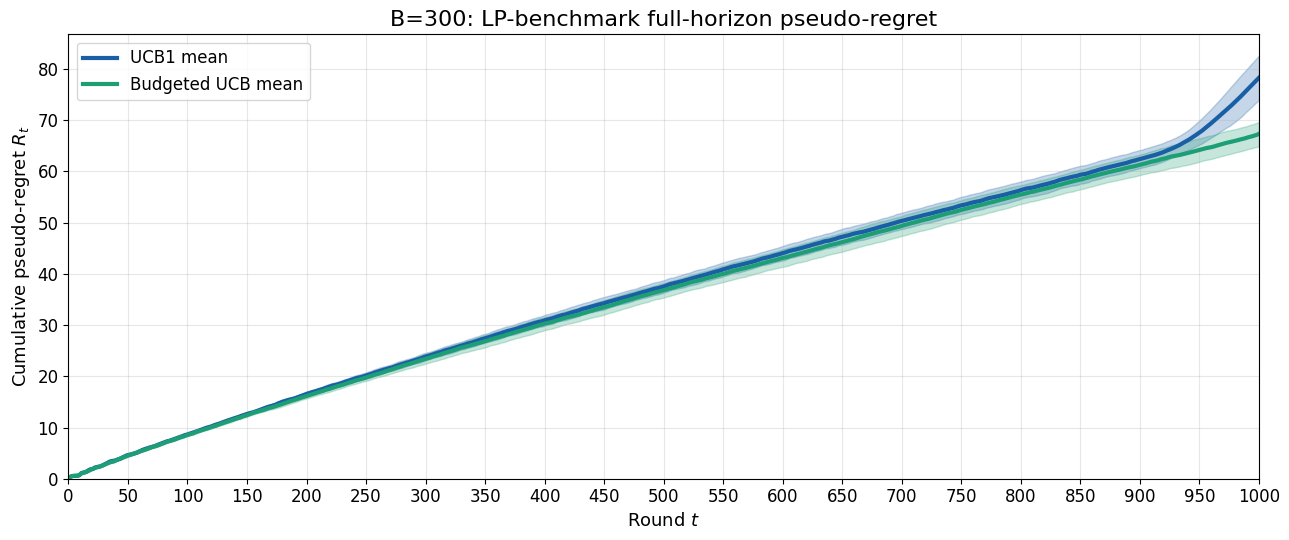

Using budget setting: official_budget_B_300
Final mean LP pseudo-regret B=300 (UCB1): 78.29
Final mean LP pseudo-regret B=300 (Budgeted UCB): 67.35


In [31]:
# Official B=300 LP-benchmark pseudo-regret over 30 seeds

budget_filter = "official_budget_B_300"

official_data = multi_seed_results[
    multi_seed_results["budget_setting"] == budget_filter
].copy()

lp_regret_B300_df, lp_bench_B300 = lp_pseudo_regret(
    data=official_data,
    bids=bids,
    value=value,
    horizon=horizon,
    initial_budget=300,
    bid_column="effective_bid",
)

show_lp_benchmark(lp_bench_B300)

pseudo_regret_df = lp_regret_B300_df.copy()

fig, ax = plt.subplots(figsize=(13, 5.5))

final_mean_pseudo_regret = {}

for algo in ["ucb1", "budgeted_ucb"]:
    color = "#185FA5" if algo == "ucb1" else "#1D9E75"
    label = "UCB1" if algo == "ucb1" else "Budgeted UCB"

    pivot = lp_regret_B300_df[
        lp_regret_B300_df["algorithm"] == algo
    ].pivot_table(
        index="round",
        columns="seed",
        values="lp_cumulative_pseudo_regret",
        aggfunc="last",
    ).sort_index()

    mean_regret = pivot.mean(axis=1).to_numpy(dtype=float)
    std_regret = pivot.std(axis=1).fillna(0).to_numpy(dtype=float)
    rounds = pivot.index.to_numpy(dtype=float)

    final_mean_pseudo_regret[algo] = mean_regret[-1]

    ax.plot(rounds, mean_regret, label=f"{label} mean", color=color, lw=3)
    ax.fill_between(
        rounds,
        mean_regret - std_regret,
        mean_regret + std_regret,
        color=color,
        alpha=0.25,
    )

ax.set_xlim(0, horizon)
ax.set_ylim(bottom=0)
ax.set_xticks(np.arange(0, horizon + 1, 50))
ax.set_xlabel("Round $t$", fontsize=13)
ax.set_ylabel("Cumulative pseudo-regret $R_t$", fontsize=13)
ax.set_title("B=300: LP-benchmark full-horizon pseudo-regret", fontsize=16)
ax.tick_params(axis="both", labelsize=12)
ax.grid(True, alpha=0.3)
ax.legend(loc="upper left", fontsize=12, frameon=True)

plt.tight_layout()
plt.savefig(
    plots_dir / "req1_lp_pseudo_regret_B300.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

print("Using budget setting:", budget_filter)
print("Final mean LP pseudo-regret B=300 (UCB1):", round(final_mean_pseudo_regret["ucb1"], 2))
print("Final mean LP pseudo-regret B=300 (Budgeted UCB):", round(final_mean_pseudo_regret["budgeted_ucb"], 2))

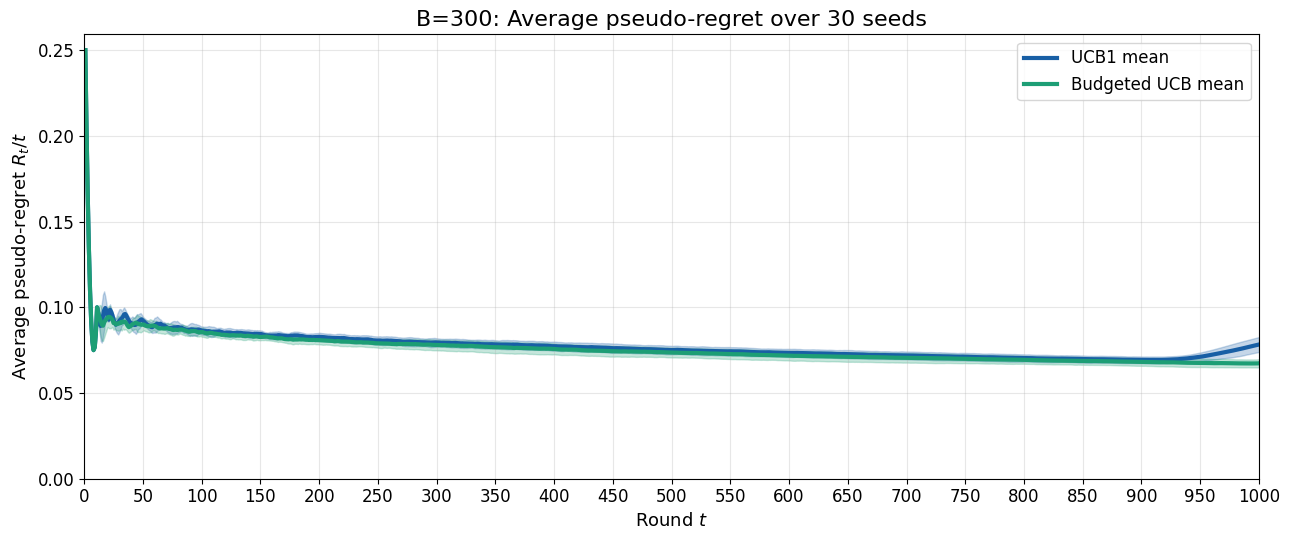

Final average pseudo-regret B=300 (UCB1): 0.0783
Final average pseudo-regret B=300 (Budgeted UCB): 0.0673


In [32]:
# Average pseudo-regret R_t / t for official B=300
# This plot is useful because sublinear regret means R_t / t decreases toward zero.

if "pseudo_regret_df" not in globals():
    raise NameError("Run the B=300 full-horizon pseudo-regret cell first.")

average_regret_df = lp_regret_B300_df.copy()
average_regret_df["average_pseudo_regret"] = average_regret_df["lp_average_pseudo_regret"]


fig, ax = plt.subplots(figsize=(13, 5.5))

final_average_pseudo_regret = {}

for algo in ["ucb1", "budgeted_ucb"]:
    color = "#185FA5" if algo == "ucb1" else "#1D9E75"
    label = "UCB1" if algo == "ucb1" else "Budgeted UCB"

    pivot = average_regret_df[
        average_regret_df["algorithm"] == algo
    ].pivot_table(
        index="round",
        columns="seed",
        values="average_pseudo_regret",
        aggfunc="last",
    ).sort_index()

    mean_average_regret = pivot.mean(axis=1).to_numpy(dtype=float)
    std_average_regret = pivot.std(axis=1).fillna(0).to_numpy(dtype=float)
    rounds = pivot.index.to_numpy(dtype=float)

    final_average_pseudo_regret[algo] = mean_average_regret[-1]

    ax.plot(
        rounds,
        mean_average_regret,
        label=f"{label} mean",
        color=color,
        lw=3,
    )

    ax.fill_between(
        rounds,
        mean_average_regret - std_average_regret,
        mean_average_regret + std_average_regret,
        color=color,
        alpha=0.25,
    )

ax.set_xlim(1, horizon)
ax.set_ylim(bottom=0)
ax.set_xticks(np.arange(0, horizon + 1, 50))
ax.set_xlabel("Round $t$", fontsize=13)
ax.set_ylabel("Average pseudo-regret $R_t / t$", fontsize=13)
ax.set_title("B=300: Average pseudo-regret over 30 seeds", fontsize=16)
ax.tick_params(axis="both", labelsize=12)
ax.grid(True, alpha=0.3)
ax.legend(loc="upper right", fontsize=12, frameon=True)

plt.tight_layout()
plt.savefig(
    plots_dir / "req1_average_pseudo_regret_B300.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

print("Final average pseudo-regret B=300 (UCB1):", round(final_average_pseudo_regret["ucb1"], 4))
print("Final average pseudo-regret B=300 (Budgeted UCB):", round(final_average_pseudo_regret["budgeted_ucb"], 4))

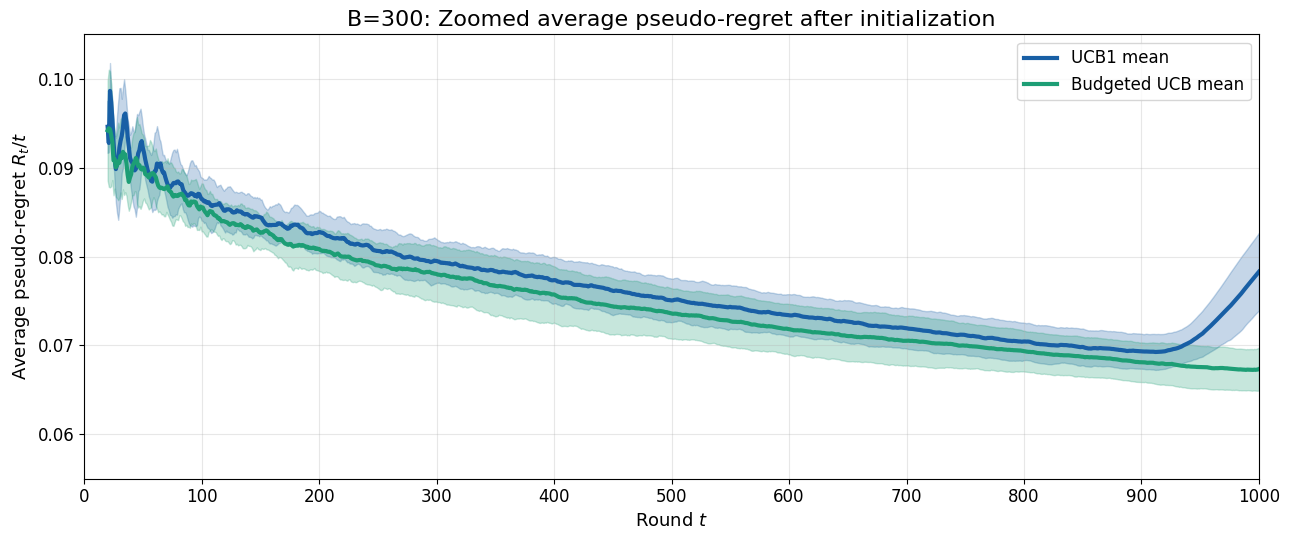

Final zoomed average pseudo-regret B=300 (UCB1): 0.0783
Final zoomed average pseudo-regret B=300 (Budgeted UCB): 0.0673


In [33]:
# Zoomed average pseudo-regret plot for readability
# We remove the first 20 rounds only from the visualization because early initialization dominates the scale.
# The data and regret computation are unchanged.

if "average_regret_df" not in globals():
    raise NameError("Run the average pseudo-regret cell first.")

zoom_start_round = 20

zoom_df = average_regret_df[
    average_regret_df["round"] >= zoom_start_round
].copy()

fig, ax = plt.subplots(figsize=(13, 5.5))

final_zoom_average_pseudo_regret = {}

for algo in ["ucb1", "budgeted_ucb"]:
    color = "#185FA5" if algo == "ucb1" else "#1D9E75"
    label = "UCB1" if algo == "ucb1" else "Budgeted UCB"

    pivot = zoom_df[
        zoom_df["algorithm"] == algo
    ].pivot_table(
        index="round",
        columns="seed",
        values="average_pseudo_regret",
        aggfunc="last",
    ).sort_index()

    mean_average_regret = pivot.mean(axis=1).to_numpy(dtype=float)
    std_average_regret = pivot.std(axis=1).fillna(0).to_numpy(dtype=float)
    rounds = pivot.index.to_numpy(dtype=float)

    final_zoom_average_pseudo_regret[algo] = mean_average_regret[-1]

    ax.plot(
        rounds,
        mean_average_regret,
        label=f"{label} mean",
        color=color,
        lw=3,
    )

    ax.fill_between(
        rounds,
        mean_average_regret - std_average_regret,
        mean_average_regret + std_average_regret,
        color=color,
        alpha=0.25,
    )

ax.set_xlim(zoom_start_round, horizon)
ax.set_ylim(0.055, 0.105)
ax.set_xticks(np.arange(0, horizon + 1, 100))
ax.set_xlabel("Round $t$", fontsize=13)
ax.set_ylabel("Average pseudo-regret $R_t/t$", fontsize=13)
ax.set_title(
    "B=300: Zoomed average pseudo-regret after initialization",
    fontsize=16,
)
ax.tick_params(axis="both", labelsize=12)
ax.grid(True, alpha=0.3)
ax.legend(loc="upper right", fontsize=12, frameon=True)

plt.tight_layout()
plt.savefig(
    plots_dir / "req1_average_pseudo_regret_B300_zoomed.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

print(
    "Final zoomed average pseudo-regret B=300 (UCB1):",
    round(final_zoom_average_pseudo_regret["ucb1"], 4),
)

print(
    "Final zoomed average pseudo-regret B=300 (Budgeted UCB):",
    round(final_zoom_average_pseudo_regret["budgeted_ucb"], 4),
)

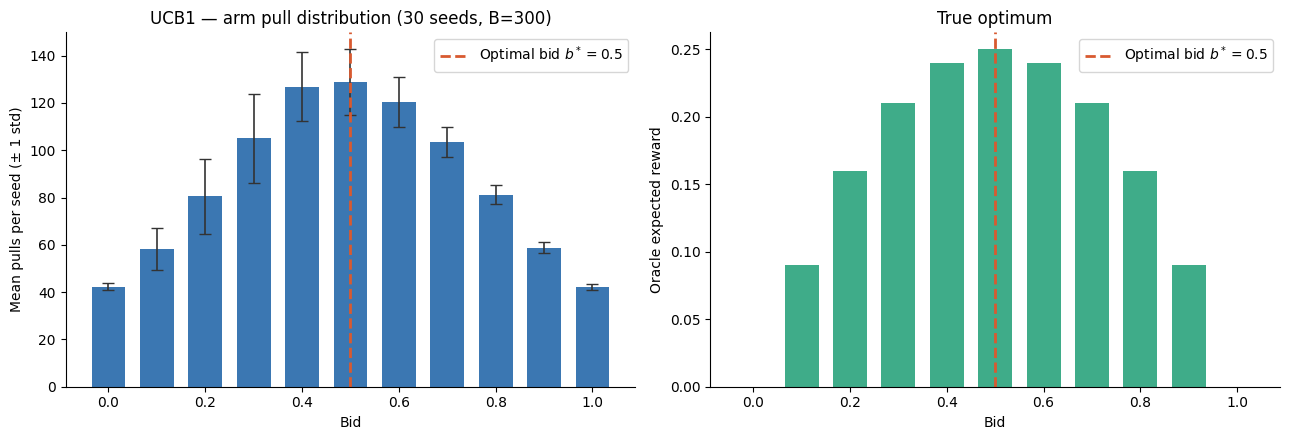

Most-pulled bid on average: 0.5
Mean share of rounds on bid 0.5: 0.136


In [34]:
# ── Arm pull distribution averaged across 30 seeds ─────────────────────────
import matplotlib.pyplot as plt
import numpy as np

# Filter only UCB1 rows from the multi-seed results
ucb1_multi = multi_seed_results[
    (multi_seed_results["algorithm"] == "ucb1") &
    (multi_seed_results["budget_setting"] == "official_budget_B_300")
]

# Count pulls per bid per seed, then average across seeds
pull_counts_per_seed = (
    ucb1_multi.groupby(["seed", "action"])
    .size()
    .reset_index(name="pulls")
)

mean_pulls = (
    pull_counts_per_seed.groupby("action")["pulls"]
    .agg(["mean", "std"])
    .reindex(bids, fill_value=0)
    .fillna(0)
)

oracle_reward = (value - bids) * bids

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Left: mean pulls per bid with error bars
axes[0].bar(bids, mean_pulls["mean"], width=0.07,
            color="#185FA5", alpha=0.85,
            yerr=mean_pulls["std"], capsize=4,
            error_kw={"linewidth": 1.2, "ecolor": "#333"})
axes[0].axvline(0.5, color="#D85A30", linestyle="--",
                linewidth=2, label="Optimal bid $b^*=0.5$")
axes[0].set_xlabel("Bid")
axes[0].set_ylabel("Mean pulls per seed (± 1 std)")
axes[0].set_title("UCB1 — arm pull distribution (30 seeds, B=300)")
axes[0].legend()
axes[0].spines[["top", "right"]].set_visible(False)

# Right: oracle expected reward (same as before)
axes[1].bar(bids, oracle_reward, width=0.07,
            color="#1D9E75", alpha=0.85)
axes[1].axvline(0.5, color="#D85A30", linestyle="--",
                linewidth=2, label="Optimal bid $b^*=0.5$")
axes[1].set_xlabel("Bid")
axes[1].set_ylabel("Oracle expected reward")
axes[1].set_title("True optimum")
axes[1].legend()
axes[1].spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(plots_dir / "req1_arm_pull_distribution_multiseed.png", dpi=200)
plt.show()

# Print summary
most_pulled = mean_pulls["mean"].idxmax()
share = mean_pulls.loc[0.5, "mean"] / mean_pulls["mean"].sum()
print(f"Most-pulled bid on average: {most_pulled}")
print(f"Mean share of rounds on bid 0.5: {round(share, 3)}")

**Interpretation.** Across 30 seeds, UCB1 should concentrate more on the analytically 
best region around \(b=0.5\). The exact pull distribution is still spread across nearby 
bids such as \(0.4\), \(0.5\), and \(0.6\), because their oracle rewards are very close:

$$
\mu(0.5)=0.25,\qquad \mu(0.4)=0.24,\qquad \mu(0.6)=0.24.
$$

So the gap between the optimal bid and its nearest neighbors is only \(0.01\). This 
makes exact arm identification difficult in finite horizon, even when the algorithm is 
learning the correct bidding region.

In [35]:
extra_plot_files = [
    "req1_multiseed_reward_official_budget.png",
    "req1_multiseed_budget_left_official_budget.png",
    "req1_multiseed_reward_tight_budget.png",
    "req1_multiseed_budget_left_tight_budget.png",
]

for filename in extra_plot_files:
    plot_path = plots_dir / filename
    print(filename, "exists:", plot_path.exists())

req1_multiseed_reward_official_budget.png exists: True
req1_multiseed_budget_left_official_budget.png exists: True
req1_multiseed_reward_tight_budget.png exists: True
req1_multiseed_budget_left_tight_budget.png exists: True


## Robustness experiment interpretation

The multi-seed experiment repeats the comparison over 30 independent stochastic 
environments. The solid lines show the average behavior, while the shaded regions 
represent plus/minus one standard deviation across seeds.

Under the official budget \(B=300\), the per-round budget is:

\[
\rho = B/T = 300/1000 = 0.30.
\]

The reward-optimal bid in the unconstrained stochastic setting is \(b=0.5\), with 
expected reward

\[
\mathbb{E}[\text{reward at } b=0.5] = 0.5(1-0.5)=0.25
\]

and expected cost

\[
\mathbb{E}[\text{cost at } b=0.5] = 0.5^2 = 0.25.
\]

Therefore, the budget is feasible in expectation for the reward-optimal bid, because

\[
0.25 < \rho = 0.30.
\]

However, with the lecture-standard UCB confidence coefficient \(2\), plain UCB1 
explores aggressively and does not pace the budget. As a result, it often exhausts the 
budget before the end of the horizon. Budgeted UCB obtains higher average reward and 
avoids early stopping by explicitly controlling spending over time.

Under the tighter budget \(B=150\), the per-round budget becomes:

\[
\rho = B/T = 150/1000 = 0.15.
\]

In this case, the reward-optimal bid \(b=0.5\) is no longer feasible in expectation, 
because its expected cost is:

\[
\mathbb{E}[\text{cost at } b=0.5] = 0.25 > 0.15.
\]

This makes the budget constraint binding. In this regime, Budgeted UCB has a clearer 
advantage because it accounts for both reward and cost, while UCB1 only learns from 
rewards and may exhaust the budget early.

After rerunning with the lecture-standard coefficient \(2\), the numerical results 
confirm this behavior:

- In the official setting \(B=300\), Budgeted UCB obtains higher average reward and 
  avoids early stopping, while UCB1 often stops before the horizon.
- In the tight-budget setting \(B=150\), the advantage of Budgeted UCB becomes much 
  stronger, because plain UCB1 spends the budget too aggressively.

## Requirement 1 completion checklist

Requirement 1 is complete for the current project configuration.

What this notebook verifies:

- The environment is a single-campaign stochastic first-price auction environment.
- The highest competing bid is sampled from a fixed distribution.
- Rewards and costs follow the first-price auction rule:
  - if the bid wins, reward is \(v-b\) and cost is \(b\);
  - otherwise reward and cost are zero.
- The bid set is finite and discrete, as required for applying UCB-style algorithms.
- UCB1 is implemented with the lecture-standard confidence coefficient \(2\).
- Plain UCB1 ignores the budget constraint when selecting bids.
- Budgeted UCB extends the UCB idea by estimating rewards and costs and solving a 
  budget-aware bid-selection problem.
- The shared CSV output format is respected.
- The generated plots compare cumulative reward, budget usage, cumulative cost, selected 
  bids, and pseudo-regret.
- The robustness experiment repeats the comparison over 30 independent seeds.
- The tight-budget stress test checks behavior when the budget constraint is binding.

Main empirical conclusion:

- In the official setting \(B=300\), the budget is relatively loose, so UCB1 can be 
  competitive with Budgeted UCB.
- Budgeted UCB is more budget-aware because it explicitly controls spending over the 
  horizon.
- In the tight-budget setting \(B=150\), the budget constraint becomes binding, and the 
  advantage of Budgeted UCB should become clearer.
- The final numerical conclusions are reported in the multi-seed summary tables and 
  pseudo-regret plots above.

## Appendix: long-horizon sanity check

This diagnostic is not part of the required Requirement 1 evaluation. It is included 
only as an additional sanity check showing how the two algorithms behave over a longer 
single-seed horizon.

The goal is to check whether the pseudo-regret grows sublinearly in practice. For a 
no-regret algorithm, the cumulative pseudo-regret \(R_t\) may still increase over time, 
but it should grow slower than linearly. Equivalently, the average pseudo-regret 
\(R_t/t\) should decrease as \(t\) becomes larger.

Therefore, in this appendix we mainly inspect whether the average pseudo-regret curve 
moves downward over the longer horizon.

Diagnostic setting: T4000_B1200
T: 4000
B: 1200.0
rho: 0.3
ucb1 round 1000 budget_left 884.6 cum_reward 171.6 cum_cost 315.4 cum_regret 70.39
ucb1 round 2000 budget_left 570.0 cum_reward 383.0 cum_cost 630.0 cum_regret 120.82
ucb1 round 3000 budget_left 283.2 cum_reward 590.2 cum_cost 916.8 cum_regret 168.39
ucb1 stopped before round 3937 because selected bid 0.7 exceeds budget_left 0.5
budgeted_ucb round 1000 budget_left 893.0 cum_reward 177.0 cum_cost 307.0 cum_regret 68.86
budgeted_ucb round 2000 budget_left 585.7 cum_reward 395.7 cum_cost 614.3 cum_regret 116.87
budgeted_ucb round 3000 budget_left 299.1 cum_reward 601.1 cum_cost 900.9 cum_regret 161.68
budgeted_ucb round 4000 budget_left 0.0 cum_reward 808.0 cum_cost 1200.0 cum_regret 207.24
budgeted_ucb finished horizon at round 4000 budget_left 0.0


,setting,algorithm,horizon,initial_budget,rho,benchmark_reward,benchmark_cost,last_played_round,stopped_by_budget,total_reward,total_cost,final_budget_left,final_pseudo_regret,final_average_pseudo_regret
0,T4000_B1200,ucb1,4000,1200.0,0.3,0.25,0.25,3936,True,794.5,1199.5,5.000000e-01,218.78,0.054695
1,T4000_B1200,budgeted_ucb,4000,1200.0,0.3,0.25,0.25,4000,False,808.0,1200.0,2.273737e-13,207.24,0.051810


Benchmark: T4000_B1200


,bid,probability,expected_reward,expected_cost
5,0.5,1.0,0.25,0.25


Arm diagnostics: T4000_B1200
----------------------------------------
ucb1


,bid,selected_count,selected_share,mean_realized_reward_when_selected,mean_realized_cost_when_selected,true_expected_reward,true_expected_cost
0,0.0,101,0.025661,0.000000,0.000000,0.00,0.00
1,0.1,171,0.043445,0.094737,0.010526,0.09,0.01
2,0.2,330,0.083841,0.181818,0.045455,0.16,0.04
3,0.3,335,0.085112,0.183881,0.078806,0.21,0.09
4,0.4,637,0.161839,0.244898,0.163265,0.24,0.16
5,0.5,830,0.210874,0.265060,0.265060,0.25,0.25
6,0.6,517,0.131352,0.227466,0.341199,0.24,0.36
7,0.7,472,0.119919,0.219280,0.511653,0.21,0.49
8,0.8,276,0.070122,0.161594,0.646377,0.16,0.64
9,0.9,166,0.042175,0.090361,0.813253,0.09,0.81


----------------------------------------
budgeted_ucb


,bid,selected_count,selected_share,mean_realized_reward_when_selected,mean_realized_cost_when_selected,true_expected_reward,true_expected_cost
0,0.0,103,0.02575,0.000000,0.000000,0.00,0.00
1,0.1,184,0.04600,0.102717,0.011413,0.09,0.01
2,0.2,300,0.07500,0.170667,0.042667,0.16,0.04
3,0.3,448,0.11200,0.212500,0.091071,0.21,0.09
4,0.4,641,0.16025,0.244306,0.162871,0.24,0.16
5,0.5,737,0.18425,0.255767,0.255767,0.25,0.25
6,0.6,591,0.14775,0.238240,0.357360,0.24,0.36
7,0.7,448,0.11200,0.213616,0.498437,0.21,0.49
8,0.8,284,0.07100,0.164789,0.659155,0.16,0.64
9,0.9,163,0.04075,0.087730,0.789571,0.09,0.81


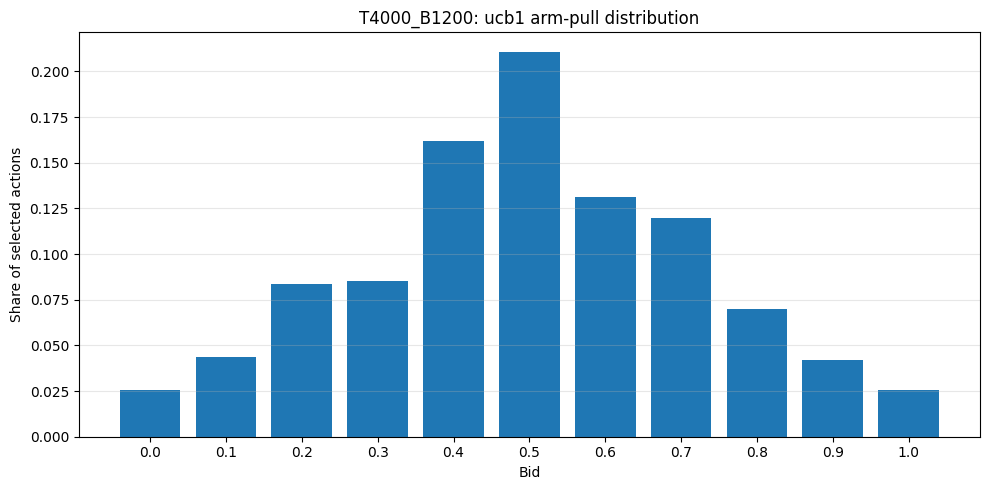

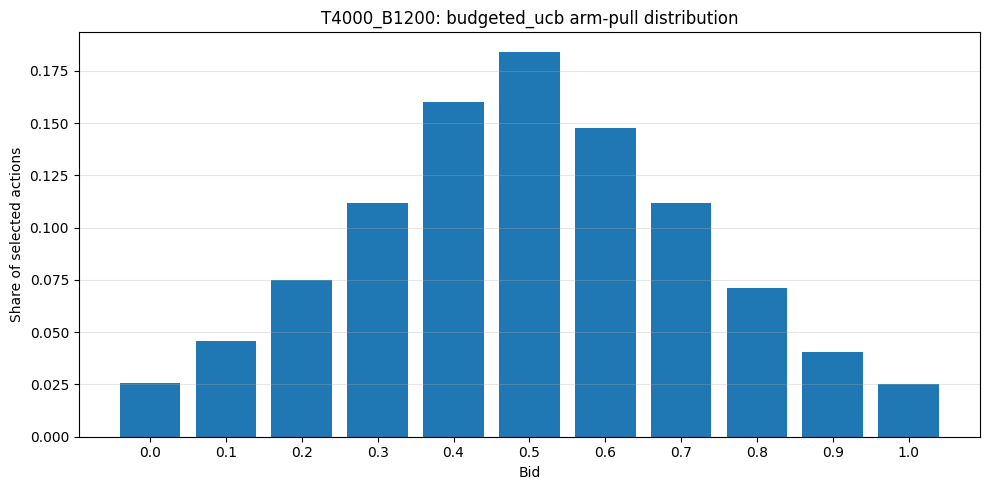

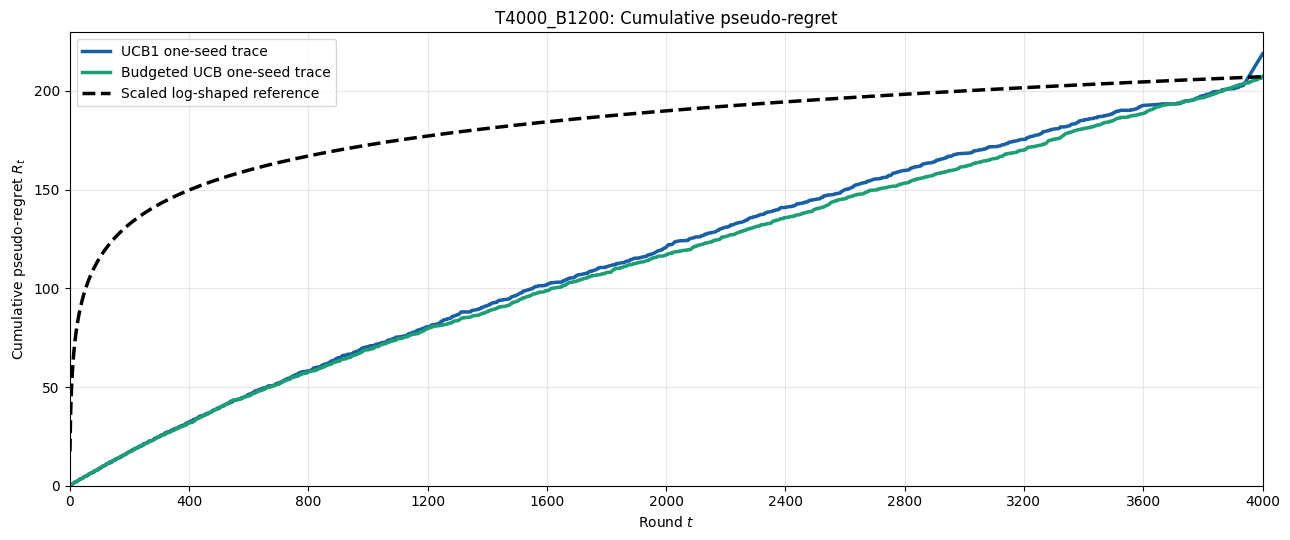

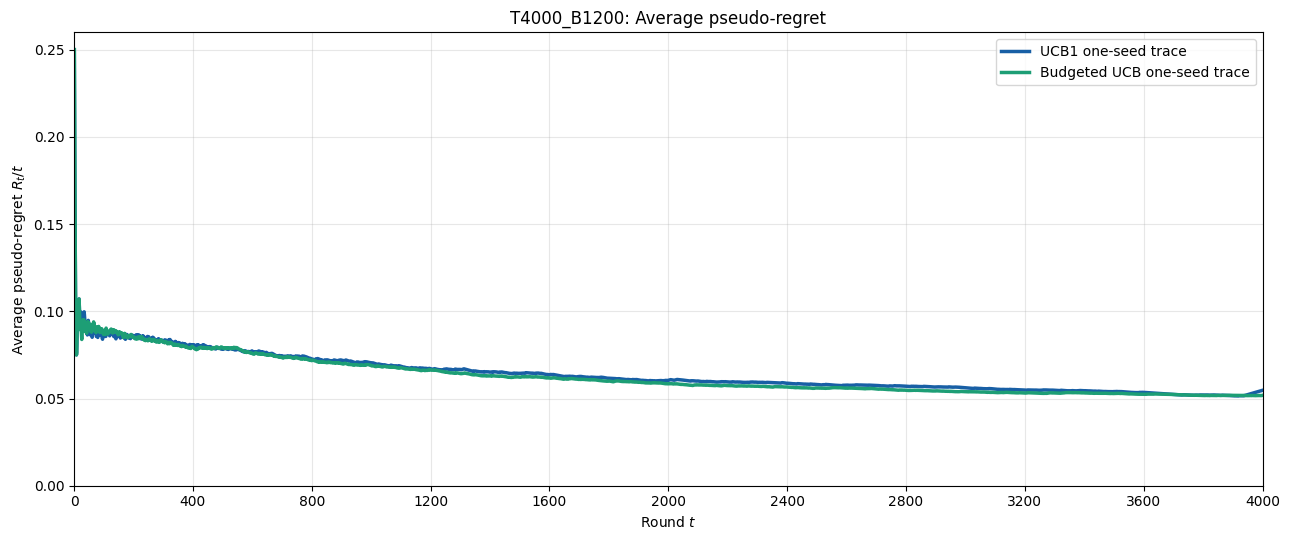

In [36]:
DIAG_SETTINGS = [
    {"horizon": 4_000, "budget": 1_200.0, "label": "T4000_B1200"},
]

DIAG_SEED = 0


def run_one_seed_diagnostic(
    algorithm_name,
    learner,
    horizon,
    initial_budget,
    random_seed,
):
    env = SingleCampaignEnvironment(
        horizon=horizon,
        initial_budget=initial_budget,
        value=value,
        min_competing_bid=min_competing_bid,
        max_competing_bid=max_competing_bid,
        random_seed=random_seed,
    )

    bench = solve_lp_benchmark(
        bids=bids,
        value=value,
        horizon=horizon,
        initial_budget=initial_budget,
    )

    benchmark_mu = bench["opt"]
    n_actions = len(bids)

    selected_counts = np.zeros(n_actions, dtype=int)
    selected_reward_sums = np.zeros(n_actions, dtype=float)
    selected_cost_sums = np.zeros(n_actions, dtype=float)

    regret_trace = np.zeros(horizon, dtype=float)
    average_regret_trace = np.zeros(horizon, dtype=float)

    cumulative_expected_reward = 0.0
    cumulative_reward = 0.0
    cumulative_cost = 0.0
    last_played_round = 0
    stopped_by_budget = False

    for t in range(1, horizon + 1):
        selected_bid = float(learner.select_action())

        matching_indices = np.where(np.isclose(bids, selected_bid))[0]
        if len(matching_indices) == 0:
            raise ValueError(f"{algorithm_name} selected non-grid bid: {selected_bid}")

        if selected_bid > env.budget_left:
            stopped_by_budget = True
            print(
                algorithm_name,
                "stopped before round",
                t,
                "because selected bid",
                selected_bid,
                "exceeds budget_left",
                round(env.budget_left, 4),
            )
            break

        action_index = int(matching_indices[0])
        result = env.step(selected_bid)

        # The environment no longer clips bids; the selected bid is the executed bid.
        effective_bid = selected_bid

        reward = float(result["reward"])
        cost = float(result["cost"])

        selected_counts[action_index] += 1
        selected_reward_sums[action_index] += reward
        selected_cost_sums[action_index] += cost

        expected_reward_selected = expected_reward(effective_bid, value)

        cumulative_expected_reward += expected_reward_selected
        cumulative_reward += reward
        cumulative_cost += cost

        cumulative_pseudo_regret = t * benchmark_mu - cumulative_expected_reward

        regret_trace[t - 1] = cumulative_pseudo_regret
        average_regret_trace[t - 1] = cumulative_pseudo_regret / t

        if algorithm_name == "ucb1":
            learner.update(selected_bid, reward)
        else:
            learner.update(selected_bid, reward, cost)

        last_played_round = t

        if t % 1_000 == 0:
            print(
                algorithm_name,
                "round",
                t,
                "budget_left",
                round(result["budget_left"], 2),
                "cum_reward",
                round(cumulative_reward, 2),
                "cum_cost",
                round(cumulative_cost, 2),
                "cum_regret",
                round(cumulative_pseudo_regret, 2),
            )

        if result["done"]:
            if t < horizon:
                stopped_by_budget = True
                print(
                    algorithm_name,
                    "stopped by budget at round",
                    t,
                    "budget_left",
                    round(result["budget_left"], 4),
                )
            else:
                print(
                    algorithm_name,
                    "finished horizon at round",
                    t,
                    "budget_left",
                    round(result["budget_left"], 4),
                )
            break

    if last_played_round < horizon:
        for t in range(last_played_round + 1, horizon + 1):
            cumulative_pseudo_regret = t * benchmark_mu - cumulative_expected_reward
            regret_trace[t - 1] = cumulative_pseudo_regret
            average_regret_trace[t - 1] = cumulative_pseudo_regret / t

    arm_diagnostics = pd.DataFrame({
        "bid": bids,
        "selected_count": selected_counts,
        "selected_share": selected_counts / max(1, selected_counts.sum()),
        "mean_realized_reward_when_selected": np.divide(
            selected_reward_sums,
            np.maximum(1, selected_counts),
        ),
        "mean_realized_cost_when_selected": np.divide(
            selected_cost_sums,
            np.maximum(1, selected_counts),
        ),
        "true_expected_reward": [expected_reward(b, value) for b in bids],
        "true_expected_cost": [expected_cost(b) for b in bids],
    })

    active_benchmark = pd.DataFrame({
        "bid": bench["bids"],
        "probability": bench["dist"],
        "expected_reward": bench["rewards"],
        "expected_cost": bench["costs"],
    })

    active_benchmark = active_benchmark[
        active_benchmark["probability"] > 1e-10
    ].copy()

    summary = {
        "algorithm": algorithm_name,
        "horizon": horizon,
        "initial_budget": initial_budget,
        "rho": initial_budget / horizon,
        "benchmark_reward": benchmark_mu,
        "benchmark_cost": bench["opt_cost"],
        "last_played_round": last_played_round,
        "stopped_by_budget": stopped_by_budget,
        "total_reward": cumulative_reward,
        "total_cost": cumulative_cost,
        "final_budget_left": initial_budget - cumulative_cost,
        "final_pseudo_regret": regret_trace[-1],
        "final_average_pseudo_regret": average_regret_trace[-1],
    }

    return {
        "summary": summary,
        "benchmark": active_benchmark,
        "arm_diagnostics": arm_diagnostics,
        "regret_trace": regret_trace,
        "average_regret_trace": average_regret_trace,
    }


diag_results = {}

for setting in DIAG_SETTINGS:
    horizon_diag = setting["horizon"]
    budget_diag = setting["budget"]
    label = setting["label"]

    print("=" * 90)
    print("Diagnostic setting:", label)
    print("T:", horizon_diag)
    print("B:", budget_diag)
    print("rho:", budget_diag / horizon_diag)

    ucb1_diag = UCB1(actions=bids, horizon=horizon_diag)

    ucb1_result = run_one_seed_diagnostic(
        algorithm_name="ucb1",
        learner=ucb1_diag,
        horizon=horizon_diag,
        initial_budget=budget_diag,
        random_seed=DIAG_SEED,
    )

    budgeted_diag = BudgetedUCB(
        actions=bids,
        horizon=horizon_diag,
        initial_budget=budget_diag,
    )

    budgeted_result = run_one_seed_diagnostic(
        algorithm_name="budgeted_ucb",
        learner=budgeted_diag,
        horizon=horizon_diag,
        initial_budget=budget_diag,
        random_seed=DIAG_SEED,
    )

    diag_results[label] = {
        "ucb1": ucb1_result,
        "budgeted_ucb": budgeted_result,
        "horizon": horizon_diag,
        "budget": budget_diag,
    }


summary_rows = []

for label, setting_results in diag_results.items():
    for algo in ["ucb1", "budgeted_ucb"]:
        row = setting_results[algo]["summary"].copy()
        row["setting"] = label
        summary_rows.append(row)

diag_summary_df = pd.DataFrame(summary_rows)

display(diag_summary_df[
    [
        "setting",
        "algorithm",
        "horizon",
        "initial_budget",
        "rho",
        "benchmark_reward",
        "benchmark_cost",
        "last_played_round",
        "stopped_by_budget",
        "total_reward",
        "total_cost",
        "final_budget_left",
        "final_pseudo_regret",
        "final_average_pseudo_regret",
    ]
])


for label, setting_results in diag_results.items():
    print("=" * 90)
    print("Benchmark:", label)
    display(setting_results["budgeted_ucb"]["benchmark"])


for label, setting_results in diag_results.items():
    print("=" * 90)
    print("Arm diagnostics:", label)

    for algo in ["ucb1", "budgeted_ucb"]:
        print("-" * 40)
        print(algo)
        display(setting_results[algo]["arm_diagnostics"])


for label, setting_results in diag_results.items():
    for algo in ["ucb1", "budgeted_ucb"]:
        arm_df = setting_results[algo]["arm_diagnostics"]

        fig, ax = plt.subplots(figsize=(10, 5))

        ax.bar(
            arm_df["bid"].astype(str),
            arm_df["selected_share"],
        )

        ax.set_xlabel("Bid")
        ax.set_ylabel("Share of selected actions")
        ax.set_title(f"{label}: {algo} arm-pull distribution")
        ax.grid(axis="y", alpha=0.3)

        plt.tight_layout()
        plt.show()


# Cumulative pseudo-regret plot
for label, setting_results in diag_results.items():
    horizon_diag = setting_results["horizon"]
    rounds = np.arange(1, horizon_diag + 1)

    fig, ax = plt.subplots(figsize=(13, 5.5))

    final_budgeted_regret = setting_results["budgeted_ucb"]["regret_trace"][-1]

    log_reference = (
        final_budgeted_regret
        * np.log(rounds + 1)
        / np.log(horizon_diag + 1)
    )

    for algo in ["ucb1", "budgeted_ucb"]:
        trace = setting_results[algo]["regret_trace"]
        color = "#185FA5" if algo == "ucb1" else "#1D9E75"
        label_name = "UCB1" if algo == "ucb1" else "Budgeted UCB"

        ax.plot(
            rounds,
            trace,
            label=f"{label_name} one-seed trace",
            color=color,
            lw=2.5,
        )

    ax.plot(
        rounds,
        log_reference,
        linestyle="--",
        color="black",
        lw=2.5,
        label="Scaled log-shaped reference",
    )

    ax.set_xlim(1, horizon_diag)
    ax.set_ylim(bottom=0)
    ax.set_xticks(np.linspace(0, horizon_diag, 11))
    ax.set_xlabel("Round $t$")
    ax.set_ylabel("Cumulative pseudo-regret $R_t$")
    ax.set_title(f"{label}: Cumulative pseudo-regret")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper left")

    plt.tight_layout()
    plt.show()


# Average pseudo-regret plot
# No log reference is shown here because the plotted quantity is R_t / t.
for label, setting_results in diag_results.items():
    horizon_diag = setting_results["horizon"]
    rounds = np.arange(1, horizon_diag + 1)

    fig, ax = plt.subplots(figsize=(13, 5.5))

    for algo in ["ucb1", "budgeted_ucb"]:
        trace = setting_results[algo]["average_regret_trace"]
        color = "#185FA5" if algo == "ucb1" else "#1D9E75"
        label_name = "UCB1" if algo == "ucb1" else "Budgeted UCB"

        ax.plot(
            rounds,
            trace,
            label=f"{label_name} one-seed trace",
            color=color,
            lw=2.5,
        )

    ax.set_xlim(1, horizon_diag)
    ax.set_ylim(bottom=0)
    ax.set_xticks(np.linspace(0, horizon_diag, 11))
    ax.set_xlabel("Round $t$")
    ax.set_ylabel("Average pseudo-regret $R_t/t$")
    ax.set_title(f"{label}: Average pseudo-regret")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right")

    plt.tight_layout()
    plt.show()